## **Clustering** delle Time Series

In [3]:
from pyts.preprocessing import MinMaxScaler
from tslearn.clustering import TimeSeriesKMeans
from sklearn.preprocessing import StandardScaler
from tslearn.generators import random_walks
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import os

In [4]:
time_series_dir = "../datasets/cleaned_times_series/"
df_ts = [] # ogni elemento e' il dataset della time series di un paziente
df_name = [] # contiene i nomi dei dataset dell'altra lista

def csv_to_df(file_name):
    file_path = os.path.join(time_series_dir, file_name)
    return pd.read_csv(file_path)


for file_name in os.listdir(time_series_dir):
    if file_name.endswith(".csv"):
        df_ts.append(csv_to_df(file_name))
        df_name.append(file_name)  # Salva il nome del file

print("File letti:", df_name)

File letti: ['10000032_40689238_cleaned.csv', '10000117_48446569_cleaned.csv', '10000764_47218930_cleaned.csv', '10000980_42546971_cleaned.csv', '10001176_40925049_cleaned.csv', '10001217_43576724_cleaned.csv', '10001401_44102194_cleaned.csv', '10002221_47422482_cleaned.csv', '10002430_43104878_cleaned.csv', '10002528_47678751_cleaned.csv', '10002557_41027618_cleaned.csv', '10002755_41117907_cleaned.csv', '10002807_44341082_cleaned.csv', '10002869_47210572_cleaned.csv', '10003019_40064176_cleaned.csv', '10003052_42157729_cleaned.csv', '10003199_42981003_cleaned.csv', '10003203_43885710_cleaned.csv', '10003299_44894948_cleaned.csv', '10003400_42017613_cleaned.csv', '10003757_40049308_cleaned.csv', '10004235_45511389_cleaned.csv', '10004322_44581770_cleaned.csv', '10004457_46167614_cleaned.csv', '10004606_42495975_cleaned.csv', '10004720_40120290_cleaned.csv', '10005606_47522493_cleaned.csv', '10005866_44420520_cleaned.csv', '10006023_45800086_cleaned.csv', '10006431_48901298_cleaned.csv

In [5]:
df_ts[0].shape

(5000, 12)

Capire quale Frequenze di campionamento usare per il calcolo della PSD su tutte le time series

LEADS: I, f: [  0.   2.   4.   6.   8.  10.  12.  14.  16.  18.  20.  22.  24.  26.
  28.  30.  32.  34.  36.  38.  40.  42.  44.  46.  48.  50.  52.  54.
  56.  58.  60.  62.  64.  66.  68.  70.  72.  74.  76.  78.  80.  82.
  84.  86.  88.  90.  92.  94.  96.  98. 100. 102. 104. 106. 108. 110.
 112. 114. 116. 118. 120. 122. 124.], psd [5.59114914e-03 3.62626054e-02 3.82066474e-02 1.84962251e-02
 1.43016309e-02 8.07699454e-03 3.07695047e-03 1.64334091e-03
 5.10046526e-04 2.40602858e-04 2.16496051e-04 1.87023490e-04
 1.47841928e-04 1.01810588e-04 8.02865248e-05 6.77205334e-05
 5.00427947e-05 3.10917608e-05 2.32798696e-05 1.79662866e-05
 1.32961623e-05 9.45279514e-06 4.35021077e-06 2.23032524e-06
 6.21756577e-07 1.09847413e-07 2.82761877e-07 7.99083318e-07
 1.22534455e-06 1.77231151e-06 2.69209290e-06 3.97095721e-06
 5.06661219e-06 6.39361673e-06 6.00095643e-06 5.96342810e-06
 6.64678129e-06 6.04113078e-06 5.94881425e-06 5.30598303e-06
 4.96915095e-06 3.88746433e-06 3.17113329e-06 2.856

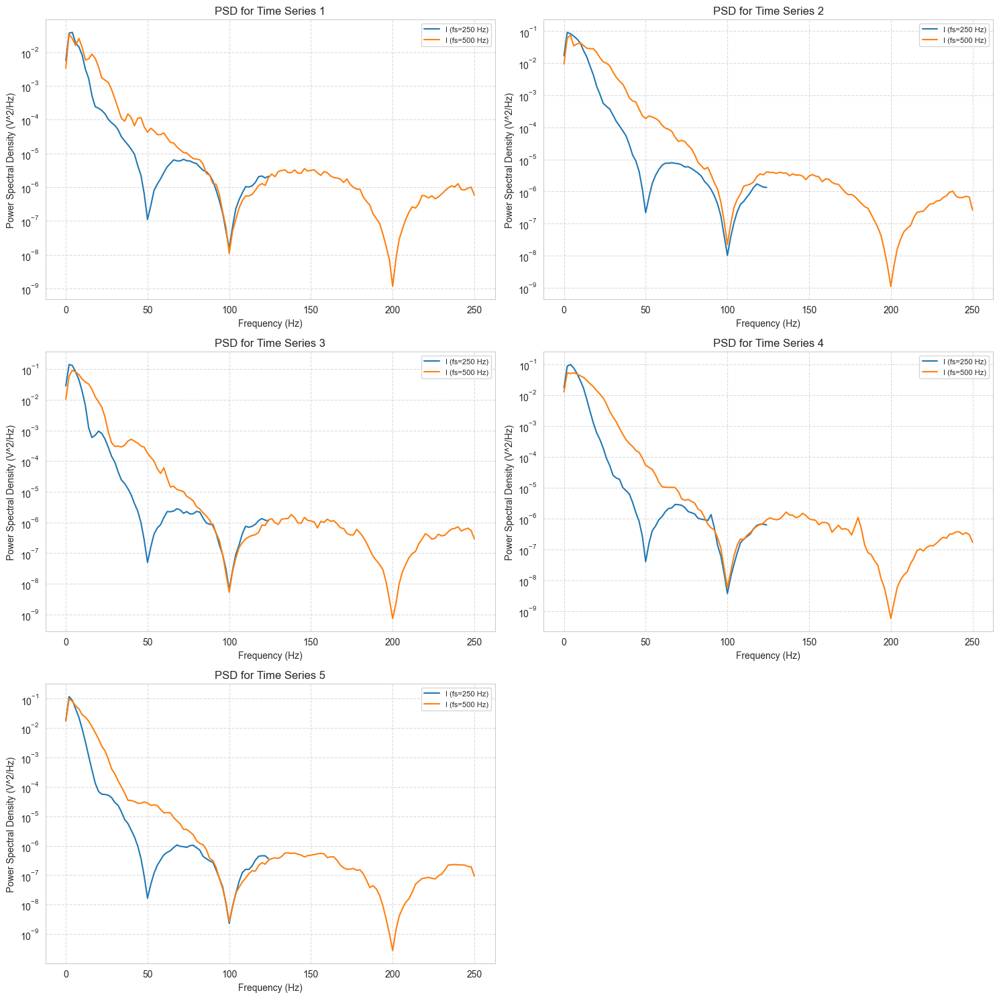

In [35]:
import numpy as np
import pandas as pd
from scipy.signal import welch
import matplotlib.pyplot as plt

# Frequenze di campionamento da considerare
fs_list = [250, 500]  # Frequenze di campionamento


# Funzione per calcolare la PSD
def compute_psd(ecg_data, fs):
    psd_results = {}
    for lead in ecg_data.columns[:1]:  # Itera sui primi 2 lead disponibili
        f, psd = welch(ecg_data[lead], fs=fs, nperseg=fs // 2)
        psd_results[lead] = (f, psd)
        print(f"LEADS: {lead}, f: {f}, psd {psd}")
    return psd_results


# Applica il calcolo PSD su tutte le time series in df_ts
num_time_series = len(df_ts[:5])  # Numero di time series da analizzare
n_cols = 2  # Numero di colonne
n_rows = -(-num_time_series // n_cols)  # Calcola il numero di righe necessarie

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
axes = axes.flatten()  # Appiattisce gli assi per iterare facilmente

for idx, ecg_data in enumerate(df_ts[:5]):  # Analizza le prime 5 time series
    ax = axes[idx]

    for fs in fs_list:
        psd_results = compute_psd(ecg_data, fs)  # Calcola la PSD per ogni frequenza

        # Plotta i risultati per ogni lead
        for lead, (frequencies, power) in psd_results.items():
            ax.semilogy(frequencies, power, label=f"{lead} (fs={fs} Hz)")

    ax.set_title(f"PSD for Time Series {idx + 1}")
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Power Spectral Density (V^2/Hz)")
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend(fontsize=8)

# Rimuovi gli assi vuoti
for i in range(num_time_series, len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()


#### E' stato deciso di usare una finestra a 250 Hz, per ridurre il rumore e semplificare l'analisi

Per racchiudere la PSD in un unico valore e' stato calcolata l'entropia di shannon cosi da creare un unica features per paziente.

In [5]:
import pandas as pd
import numpy as np
from scipy.signal import welch
from scipy.stats import entropy

# Supponiamo di avere una lista di DataFrame df_ts (time series dei pazienti)
fs = 500  # Frequenza di campionamento
shannon_entropy_list = []

# Itera su ogni paziente (ogni elemento di df_ts)
for idx, ecg_data in enumerate(df_ts):
    patient_entropy = {}
    patient_entropy['Patient_ID'] = df_name[idx]
    for lead in ecg_data.columns:  # Itera su tutti i lead disponibili
        # Calcola la PSD usando Welch
        f, psd = welch(ecg_data[lead], fs=fs, nperseg=fs // 2)
        # Normalizza la PSD
        psd_normalized = psd / np.sum(psd)
        # Calcola l'entropia di Shannon
        shannon_entropy = entropy(psd_normalized, base=2)
        patient_entropy[lead] = shannon_entropy
    shannon_entropy_list.append(patient_entropy)

# Crea un DataFrame con i risultati
df_shannon_entropy = pd.DataFrame(shannon_entropy_list)

# Salva in un file CSV
csv_filename = 'shannon_entropy_per_lead.csv'
df_shannon_entropy.to_csv(csv_filename, index=False)
# 
# # Output
df_shannon_entropy


,Patient_ID,I,II,III,aVR,aVF,aVL,V1,V2,V3,V4,V5,V6
0,10000032_40689238_cleaned.csv,3.373993,3.491854,3.523391,3.479883,3.508647,3.482638,3.229407,2.971753,3.176519,3.683979,3.702386,3.488588
1,10000117_48446569_cleaned.csv,3.877928,3.722291,3.698656,3.730135,3.713659,3.678993,3.609070,3.556012,3.918204,3.830537,3.749432,3.690658
2,10000764_47218930_cleaned.csv,3.331620,3.187845,3.439108,3.235782,3.197782,3.574641,3.371315,3.539386,3.846341,3.478911,3.312537,3.250132
3,10000980_42546971_cleaned.csv,3.673899,3.677237,3.590669,3.671492,3.259931,3.693253,3.255230,3.220324,3.119380,3.933629,3.751128,3.452136
4,10001176_40925049_cleaned.csv,3.085620,3.665378,2.906351,3.562469,3.318331,2.757877,3.466500,3.051839,3.576293,3.661007,3.675933,3.691627
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1082,10275673_49386477_cleaned.csv,3.571584,3.736245,4.071616,3.579305,4.265649,3.692630,3.339306,3.073694,3.958494,3.880988,3.818059,3.746241
1083,10275681_46114566_cleaned.csv,2.372495,2.590005,2.381495,2.482874,2.491543,2.348433,2.531413,2.445390,2.410246,2.431256,2.396149,2.340677
1084,10275752_46043287_cleaned.csv,3.631256,3.058495,3.570049,3.634565,3.357229,3.590784,3.669307,3.365729,2.863305,3.265168,3.666356,3.764370
1085,10275937_40123194_cleaned.csv,3.654538,3.554804,4.622576,3.544318,3.888734,3.974337,4.021778,4.148167,4.195380,3.966918,3.445261,3.440769


---
### Normalizzazione dei dati elaborati 12 colonne con 1087 righe, una per paziente

In [7]:
df_shannon_entropy = pd.read_csv('shannon_entropy_per_lead.csv')

In [8]:
from itertools import combinations

# Lista completa delle feature numeriche
numerical_features = ['I', 'II', 'III', 'aVR', 'aVF', 'aVL', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']

# Gruppi di feature correlate
feature_groups = []


# Funzione per filtrare le combinazioni
def filter_combinations(features, groups, min_len, max_len):
    valid_combinations = []
    for r in range(min_len, max_len + 1):
        for combo in combinations(features, r):
            # Verifica che non ci siano più di un elemento per ogni gruppo
            if all(sum(1 for f in combo if f in group) <= 1 for group in groups):
                valid_combinations.append(list(combo))
    return valid_combinations


# Ottieni le combinazioni filtrate
filtered_combinations = filter_combinations(numerical_features, feature_groups, 5, 12)

# Stampa o salva le combinazioni
print(f"Generated {len(filtered_combinations)} valid combinations.")
for combo in filtered_combinations[:10]:  # Modifica l'indice per vedere più combinazioni
    print(combo)
print('len:', len(filtered_combinations))

Generated 3302 valid combinations.
['I', 'II', 'III', 'aVR', 'aVF']
['I', 'II', 'III', 'aVR', 'aVL']
['I', 'II', 'III', 'aVR', 'V1']
['I', 'II', 'III', 'aVR', 'V2']
['I', 'II', 'III', 'aVR', 'V3']
['I', 'II', 'III', 'aVR', 'V4']
['I', 'II', 'III', 'aVR', 'V5']
['I', 'II', 'III', 'aVR', 'V6']
['I', 'II', 'III', 'aVF', 'aVL']
['I', 'II', 'III', 'aVF', 'V1']
len: 3302


---
## K-Means
### Silouhette e Davies

In [88]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import pandas as pd

# Inizializza una lista per memorizzare i risultati
results = []

# Dizionario dei metodi di normalizzazione
normalization_methods = {
    "MinMax": MinMaxScaler(),
    "ZScore": StandardScaler()
}

# Itera sui metodi di normalizzazione
for norm_name, scaler in normalization_methods.items():
    for i, features in enumerate(filtered_combinations):
        # Normalizza i dati
        normalized_patients_df = pd.DataFrame(scaler.fit_transform(df_shannon_entropy[features]), columns=features)
        print(f'{i} | features: {features} | Normalization: {norm_name}')

        # Prova con diversi numeri di cluster
        for n_clusters in range(2, 4):
            kmeans = KMeans(n_clusters=n_clusters, random_state=42)
            kmeans.fit(normalized_patients_df)

            # Calcola il numero di punti in ogni cluster
            cluster_counts = pd.Series(kmeans.labels_).value_counts().to_dict()

            # Calcola Silhouette Score e Davies-Bouldin Index
            silhouette_all = silhouette_score(normalized_patients_df, kmeans.labels_)
            kmeans_db = davies_bouldin_score(normalized_patients_df, kmeans.labels_)

            print(
                f"Number of clusters: {n_clusters} | Silhouette Score: {silhouette_all:.3f} | Davies-Bouldin Index: {kmeans_db:.3f} | Cluster Counts: {cluster_counts}")

            # Memorizza i risultati
            results.append({
                "Features": features,
                "n_clusters": n_clusters,
                "Normalization": norm_name,
                "Silhouette": silhouette_all,
                "Davies_Bouldin": kmeans_db,
                "Cluster_Counts": cluster_counts
            })

# Converte i risultati in un DataFrame
results_df = pd.DataFrame(results)

# Salva i risultati in un file CSV
results_df.to_csv("TS_kmeans_silhouette_davies_cluster_counts.csv", index=False)

print("Risultati salvati in TS_kmeans_silhouette_davies_cluster_counts.csv")


0 | features: ['I', 'II', 'III', 'aVR', 'aVF'] | Normalization: MinMax
Number of clusters: 2 | Silhouette Score: 0.408 | Davies-Bouldin Index: 1.019 | Cluster Counts: {1: 799, 0: 288}
Number of clusters: 3 | Silhouette Score: 0.283 | Davies-Bouldin Index: 1.157 | Cluster Counts: {0: 487, 1: 486, 2: 114}
1 | features: ['I', 'II', 'III', 'aVR', 'aVL'] | Normalization: MinMax
Number of clusters: 2 | Silhouette Score: 0.437 | Davies-Bouldin Index: 0.959 | Cluster Counts: {1: 841, 0: 246}
Number of clusters: 3 | Silhouette Score: 0.298 | Davies-Bouldin Index: 1.106 | Cluster Counts: {1: 565, 0: 431, 2: 91}
2 | features: ['I', 'II', 'III', 'aVR', 'V1'] | Normalization: MinMax
Number of clusters: 2 | Silhouette Score: 0.411 | Davies-Bouldin Index: 1.041 | Cluster Counts: {1: 827, 0: 260}
Number of clusters: 3 | Silhouette Score: 0.278 | Davies-Bouldin Index: 1.203 | Cluster Counts: {1: 553, 0: 435, 2: 99}
3 | features: ['I', 'II', 'III', 'aVR', 'V2'] | Normalization: MinMax
Number of clusters

In [76]:
results_df.to_csv("TS_kmeans_silhouette_davies_cluster_counts.csv", index=False)

In [11]:
results_df

,Features,n_clusters,Normalization,Silhouette,Davies_Bouldin,Cluster_Counts
0,"['I', 'II', 'III', 'aVR', 'aVF']",2,MinMax,0.407710,1.019082,"{1: 799, 0: 288}"
1,"['I', 'II', 'III', 'aVR', 'aVF']",3,MinMax,0.283321,1.156855,"{0: 487, 1: 486, 2: 114}"
2,"['I', 'II', 'III', 'aVR', 'aVL']",2,MinMax,0.436596,0.958968,"{1: 841, 0: 246}"
3,"['I', 'II', 'III', 'aVR', 'aVL']",3,MinMax,0.297745,1.106304,"{1: 565, 0: 431, 2: 91}"
4,"['I', 'II', 'III', 'aVR', 'V1']",2,MinMax,0.411265,1.041204,"{1: 827, 0: 260}"
...,...,...,...,...,...,...
13203,"['I', 'III', 'aVR', 'aVF', 'aVL', 'V1', 'V2', ...",3,ZScore,0.233742,1.377146,"{2: 578, 0: 418, 1: 91}"
13204,"['II', 'III', 'aVR', 'aVF', 'aVL', 'V1', 'V2',...",2,ZScore,0.474435,0.975844,"{1: 932, 0: 155}"
13205,"['II', 'III', 'aVR', 'aVF', 'aVL', 'V1', 'V2',...",3,ZScore,0.233476,1.381811,"{1: 556, 0: 433, 2: 98}"
13206,"['I', 'II', 'III', 'aVR', 'aVF', 'aVL', 'V1', ...",2,ZScore,0.480720,0.964896,"{1: 938, 0: 149}"


In [10]:
import pandas as pd
import ast

# Carica il DataFrame con i risultati
results_df = pd.read_csv("TS_kmeans_silhouette_davies_cluster_counts.csv")  # Modifica il nome del file se necessario

# Filtra i risultati con n_clusters=2
filtered_df = results_df[results_df['n_clusters'] == 2].copy()

# Converti Cluster_Counts in dict se necessario
filtered_df['Cluster_Counts'] = filtered_df['Cluster_Counts'].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

# Calcola la differenza tra i punti nei cluster
filtered_df['Cluster_Difference'] = filtered_df['Cluster_Counts'].apply(
    lambda x: max(x.values()) - min(x.values()) if isinstance(x, dict) else None
)

# Filtra i risultati scartando quelli con differenza >= 1000
filtered_df = filtered_df[filtered_df['Cluster_Difference'] < 1000]

# Ordina i risultati per differenza minima
sorted_df = filtered_df.sort_values(by='Cluster_Difference', ascending=True)
sorted_df


,Features,n_clusters,Normalization,Silhouette,Davies_Bouldin,Cluster_Counts,Cluster_Difference
868,"['II', 'aVR', 'aVF', 'V5', 'V6']",2,MinMax,0.420923,0.967181,"{1: 763, 0: 324}",439
668,"['II', 'III', 'aVR', 'aVF', 'V4']",2,MinMax,0.398120,1.038817,"{1: 767, 0: 320}",447
670,"['II', 'III', 'aVR', 'aVF', 'V5']",2,MinMax,0.406782,1.011415,"{1: 777, 0: 310}",467
672,"['II', 'III', 'aVR', 'aVF', 'V6']",2,MinMax,0.407867,1.008239,"{1: 782, 0: 305}",477
666,"['II', 'III', 'aVR', 'aVF', 'V3']",2,MinMax,0.383887,1.086431,"{1: 782, 0: 305}",477
...,...,...,...,...,...,...,...
3372,"['aVR', 'V1', 'V3', 'V4', 'V5', 'V6']",2,MinMax,0.552028,0.844339,"{1: 960, 0: 127}",833
4296,"['I', 'aVR', 'V1', 'V3', 'V4', 'V5', 'V6']",2,MinMax,0.547249,0.854300,"{0: 961, 1: 126}",835
1580,"['V1', 'V3', 'V4', 'V5', 'V6']",2,MinMax,0.561304,0.818630,"{0: 962, 1: 125}",837
7252,"['I', 'V1', 'V4', 'V5', 'V6']",2,ZScore,0.562614,0.827683,"{0: 962, 1: 125}",837


In [12]:
sorted_df

,Features,n_clusters,Normalization,Silhouette,Davies_Bouldin,Cluster_Counts,Cluster_Difference
868,"['II', 'aVR', 'aVF', 'V5', 'V6']",2,MinMax,0.420923,0.967181,"{1: 763, 0: 324}",439
668,"['II', 'III', 'aVR', 'aVF', 'V4']",2,MinMax,0.398120,1.038817,"{1: 767, 0: 320}",447
670,"['II', 'III', 'aVR', 'aVF', 'V5']",2,MinMax,0.406782,1.011415,"{1: 777, 0: 310}",467
672,"['II', 'III', 'aVR', 'aVF', 'V6']",2,MinMax,0.407867,1.008239,"{1: 782, 0: 305}",477
666,"['II', 'III', 'aVR', 'aVF', 'V3']",2,MinMax,0.383887,1.086431,"{1: 782, 0: 305}",477
...,...,...,...,...,...,...,...
3372,"['aVR', 'V1', 'V3', 'V4', 'V5', 'V6']",2,MinMax,0.552028,0.844339,"{1: 960, 0: 127}",833
4296,"['I', 'aVR', 'V1', 'V3', 'V4', 'V5', 'V6']",2,MinMax,0.547249,0.854300,"{0: 961, 1: 126}",835
1580,"['V1', 'V3', 'V4', 'V5', 'V6']",2,MinMax,0.561304,0.818630,"{0: 962, 1: 125}",837
7252,"['I', 'V1', 'V4', 'V5', 'V6']",2,ZScore,0.562614,0.827683,"{0: 962, 1: 125}",837


---
## K-Means - Scelta del set di features

C:\Users\ironl\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
C:\Users\ironl\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
C:\Users\ironl\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
C:\Users\ironl\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
C:\Users\ironl\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
C:\Us

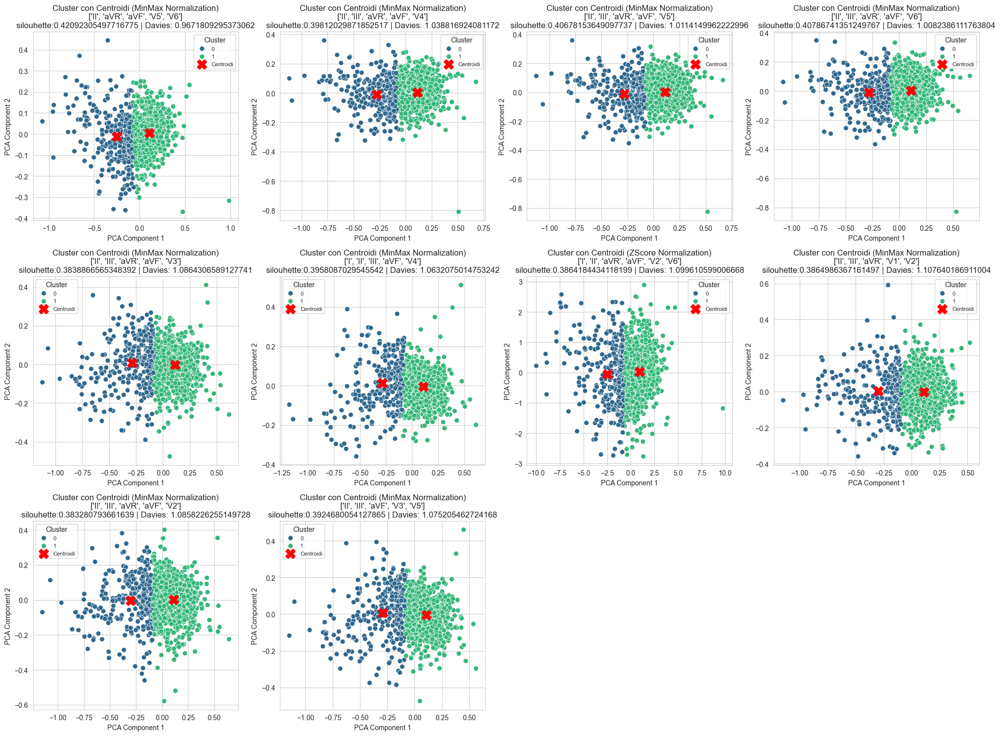

In [109]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Scegli il valore ottimale di K
n_clusters = 2  # Cambia con il valore ottimale trovato

# Numero di grafici per riga
n_cols = 4
n_rows = -(-len(sorted_df.iloc[:10]) // n_cols)  # Calcola il numero di righe necessarie

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5 * n_rows))
axes = axes.flatten()  # Appiattisci gli assi per iterare facilmente

# Itera sui primi 10 set di features dalla tabella sorted_df
for idx, row in enumerate(sorted_df.iloc[:10].itertuples(index=False)):
    features = row.Features
    normalization_method = row.Normalization

    # Scegli il metodo di normalizzazione
    if normalization_method == 'MinMax':
        scaler = MinMaxScaler()
    elif normalization_method == 'ZScore':
        scaler = StandardScaler()
    else:
        raise ValueError(f"Metodo di normalizzazione non valido: {normalization_method}")

    # Normalizza i dati
    normalized_patients_df = pd.DataFrame(scaler.fit_transform(df_shannon_entropy[features]), columns=features)

    # Esegui il clustering con KMeans
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans.fit(normalized_patients_df)

    # Riduci i dati a 2 dimensioni con PCA
    pca = PCA(n_components=2)
    data_2d = pca.fit_transform(normalized_patients_df)

    # Riduci i centroidi dei cluster a 2 dimensioni con PCA
    centroids_2d = pca.transform(kmeans.cluster_centers_)

    # Aggiungi i risultati PCA ai dati
    pca_df = pd.DataFrame(data_2d, columns=['PCA1', 'PCA2'])
    pca_df['cluster'] = kmeans.labels_

    # Visualizza cluster e centroidi
    ax = axes[idx]
    sns.scatterplot(ax=ax, data=pca_df, x='PCA1', y='PCA2', hue='cluster', palette='viridis', s=50)
    ax.scatter(centroids_2d[:, 0], centroids_2d[:, 1], s=200, c='red', marker='X', label='Centroidi')
    ax.set_title(
        f'Cluster con Centroidi ({normalization_method} Normalization)\n{features}\nsilouhette:{row.Silhouette} | Davies: {row.Davies_Bouldin}')
    ax.set_xlabel('PCA Component 1')
    ax.set_ylabel('PCA Component 2')
    ax.legend(title='Cluster', fontsize=8)

# Rimuovi eventuali assi vuoti
for i in range(len(sorted_df.iloc[:10]), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()


Verra' considerato il terzo essendo il miglior compromesso tra Davies, silouhette, distribuzione dei punti nei cluster. [II, III, aVR, aVF, V6]
Per cui l'analisi verra' fatta con min max normalization

In [110]:
sorted_df[:4]

,Features,n_clusters,Normalization,Silhouette,Davies_Bouldin,Cluster_Counts,Cluster_Difference
868,"[II, aVR, aVF, V5, V6]",2,MinMax,0.420923,0.967181,"{1: 763, 0: 324}",439
668,"[II, III, aVR, aVF, V4]",2,MinMax,0.398120,1.038817,"{1: 767, 0: 320}",447
670,"[II, III, aVR, aVF, V5]",2,MinMax,0.406782,1.011415,"{1: 777, 0: 310}",467
672,"[II, III, aVR, aVF, V6]",2,MinMax,0.407867,1.008239,"{1: 782, 0: 305}",477


---
### Merge dati time series con tabulari
Estrapolazione dei 1087 dai dati tabulari per analisi dei cluster

In [47]:
patients_df = pd.read_csv('../datasets/general_patients_TAB.csv')
df_shannon_entropy = pd.read_csv('shannon_entropy_per_lead.csv')
features = ['Patient_ID', 'II', 'III', 'aVR', 'aVF', 'V6']  # {1: 777, 0: 310}
df_shannon_entropy = df_shannon_entropy[features]

In [147]:
patients_df

,study_id,subject_id,diagnosis,gender,age,dod,age_range,diagnosis_categories,num_categories,temperature_min,...,temperature_class_max,o2sat_class_mean,o2sat_class_min,mean_arterial_pressure_class_mean,mean_arterial_pressure_class_min,mean_arterial_pressure_class_max,RR_HR_ratio_class_mean,RR_HR_ratio_class_min,RR_HR_ratio_class_max,age_range_class
0,40689238,10000032,"['K7469', 'E871', 'R64', 'E875', 'I9581', 'J44...",1,52.0,1,40-60,"['A00-B99', 'I00-I99', 'K00-K95', 'V00-Y99', '...",9,97.7,...,normale,normale,basso,normale,ipotensione,normale,Normale,Normale,Normale,50-60
1,48446569,10000117,"['E7800', 'K219', 'Z87442', 'S72012A', 'I341',...",1,57.0,0,40-60,"['M00-M99', 'I00-I99', 'K00-K95', 'G00-G99', '...",9,97.1,...,normale,normale,basso,normale,ipotensione,ipertensione,Normale,Normale,Normale,50-60
2,47218930,10000764,"['R040', 'D696', 'I252', 'E785', 'I214', 'E780...",0,86.0,0,80-100,"['I00-I99', 'N00-N99', 'V00-Y99', 'Z00-Z99', '...",8,97.6,...,normale,normale,basso,normale,normale,normale,Normale,Normale,Normale,80-90
3,42546971,10000980,"['I248', 'E785', 'Z794', 'Z8673', 'J449', 'E11...",1,75.0,1,60-80,"['I00-I99', 'N00-N99', 'Z00-Z99', 'J00-J99', '...",5,94.8,...,normale,normale,normale,ipertensione,normale,ipertensione,Normale,Normale,Alto,70-80
4,40925049,10001176,"['E871', 'R740', 'D649', 'E785', 'I10', 'K219'...",1,64.0,0,60-80,"['I00-I99', 'K00-K95', 'G00-G99', 'D50-D89', '...",8,98.0,...,febbre,normale,basso,normale,normale,normale,Normale,Normale,Normale,60-70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39472,41514157,19998350,"['J45998', 'G4733', 'E119', 'R0789', 'F419', '...",0,53.0,0,40-60,"['I00-I99', 'G00-G99', 'Z00-Z99', 'J00-J99', '...",7,97.2,...,normale,normale,basso,normale,normale,ipertensione,Normale,Normale,Alto,50-60
39473,43267699,19998444,"['Z9049', 'F39', 'K219', 'F1021', 'R3911', 'K8...",0,38.0,0,20-40,"['K00-K95', 'G00-G99', 'Z00-Z99', 'F01-F99', '...",5,96.8,...,normale,normale,basso,normale,normale,ipertensione,Normale,Normale,Normale,30-40
39474,40314343,19999156,"['R079', 'F419']",1,62.0,0,60-80,"['F01-F99', 'R00-R99']",2,97.0,...,normale,normale,normale,normale,normale,ipertensione,Normale,Normale,Normale,60-70
39475,42489677,19999733,"['T7840XA', 'Y92099']",1,19.0,0,0-20,"['V00-Y99', 'S00-T88']",2,98.0,...,normale,normale,normale,normale,ipotensione,normale,Normale,Normale,Normale,0-30


In [113]:
df_shannon_entropy

,Patient_ID,I,II,III,aVR,aVF,aVL,V1,V2,V3,V4,V5,V6,cluster_MinMax,cluster_ZScore
0,10000032_40689238_cleaned.csv,3.373993,3.491854,3.523391,3.479883,3.508647,3.482638,3.229407,2.971753,3.176519,3.683979,3.702386,3.488588,0,1
1,10000117_48446569_cleaned.csv,3.877928,3.722291,3.698656,3.730135,3.713659,3.678993,3.609070,3.556012,3.918204,3.830537,3.749432,3.690658,0,1
2,10000764_47218930_cleaned.csv,3.331620,3.187845,3.439108,3.235782,3.197782,3.574641,3.371315,3.539386,3.846341,3.478911,3.312537,3.250132,0,1
3,10000980_42546971_cleaned.csv,3.673899,3.677237,3.590669,3.671492,3.259931,3.693253,3.255230,3.220324,3.119380,3.933629,3.751128,3.452136,0,1
4,10001176_40925049_cleaned.csv,3.085620,3.665378,2.906351,3.562469,3.318331,2.757877,3.466500,3.051839,3.576293,3.661007,3.675933,3.691627,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1082,10275673_49386477_cleaned.csv,3.571584,3.736245,4.071616,3.579305,4.265649,3.692630,3.339306,3.073694,3.958494,3.880988,3.818059,3.746241,0,1
1083,10275681_46114566_cleaned.csv,2.372495,2.590005,2.381495,2.482874,2.491543,2.348433,2.531413,2.445390,2.410246,2.431256,2.396149,2.340677,1,0
1084,10275752_46043287_cleaned.csv,3.631256,3.058495,3.570049,3.634565,3.357229,3.590784,3.669307,3.365729,2.863305,3.265168,3.666356,3.764370,0,1
1085,10275937_40123194_cleaned.csv,3.654538,3.554804,4.622576,3.544318,3.888734,3.974337,4.021778,4.148167,4.195380,3.966918,3.445261,3.440769,0,1


In [48]:
# Funzione per estrarre subject_id
def extract_ids(patient_id):
    try:
        subject_id, study_id = patient_id.split('_')[0], patient_id.split('_')[1]
        return pd.Series({'subject_id': subject_id})
    except Exception as e:
        print(f"Errore con Patient_ID: {patient_id}. Dettagli: {e}")
        return pd.Series({'subject_id': None})


# Applica la funzione alla colonna PATIENT_ID
df_shannon_entropy[['subject_id']] = df_shannon_entropy['Patient_ID'].apply(extract_ids)
df_shannon_entropy.drop('Patient_ID', inplace=True, axis=1)

# Mostra un'anteprima del DataFrame
print(df_shannon_entropy.head())

         II       III       aVR       aVF        V6 subject_id
0  3.491854  3.523391  3.479883  3.508647  3.488588   10000032
1  3.722291  3.698656  3.730135  3.713659  3.690658   10000117
2  3.187845  3.439108  3.235782  3.197782  3.250132   10000764
3  3.677237  3.590669  3.671492  3.259931  3.452136   10000980
4  3.665378  2.906351  3.562469  3.318331  3.691627   10001176


In [153]:
df_shannon_entropy

,II,III,aVR,aVF,V6,subject_id
0,3.491854,3.523391,3.479883,3.508647,3.488588,10000032
1,3.722291,3.698656,3.730135,3.713659,3.690658,10000117
2,3.187845,3.439108,3.235782,3.197782,3.250132,10000764
3,3.677237,3.590669,3.671492,3.259931,3.452136,10000980
4,3.665378,2.906351,3.562469,3.318331,3.691627,10001176
...,...,...,...,...,...,...
1082,3.736245,4.071616,3.579305,4.265649,3.746241,10275673
1083,2.590005,2.381495,2.482874,2.491543,2.340677,10275681
1084,3.058495,3.570049,3.634565,3.357229,3.764370,10275752
1085,3.554804,4.622576,3.544318,3.888734,3.440769,10275937


In [49]:
import pandas as pd

# Assicurati che 'subject_id' sia presente e formattata correttamente in entrambi i DataFrame
patients_df['subject_id'] = patients_df['subject_id'].astype(str)
df_shannon_entropy['subject_id'] = df_shannon_entropy['subject_id'].astype(str)

# Unisci i due DataFrame mantenendo solo le righe presenti in entrambi (inner join)
patients_df = pd.merge(patients_df, df_shannon_entropy, on='subject_id', how='inner')

# Controlla il risultato
print(f"Numero di righe nel DataFrame unito: {patients_df.shape[0]}")
patients_df.head()
patients_df.drop("study_id", axis=1, inplace=True)

Numero di righe nel DataFrame unito: 1031


In [50]:
patients_df.to_csv("merged_patients_shannon.csv", index=False)

In [243]:
patients_df

,subject_id,diagnosis,gender,age,dod,age_range,diagnosis_categories,num_categories,temperature_min,temperature_max,...,mean_arterial_pressure_class_max,RR_HR_ratio_class_mean,RR_HR_ratio_class_min,RR_HR_ratio_class_max,age_range_class,II,III,aVR,aVF,V6
0,10000032,"['K7469', 'E871', 'R64', 'E875', 'I9581', 'J449', 'R188', 'V462', 'F17200', 'Z21', 'B182', 'F319', 'Z66']",1,52.0,1,40-60,"['A00-B99', 'I00-I99', 'K00-K95', 'V00-Y99', 'Z00-Z99', 'J00-J99', 'F01-F99', 'E00-E89', 'R00-R99']",9,97.7,99.4,...,normale,Normale,Normale,Normale,50-60,3.491854,3.523391,3.479883,3.508647,3.488588
1,10000117,"['E7800', 'K219', 'Z87442', 'S72012A', 'I341', 'Z7901', 'Y93K1', 'W010XXA', 'F419', 'Z87891', 'Y92480', 'G43909', 'M810']",1,57.0,0,40-60,"['M00-M99', 'I00-I99', 'K00-K95', 'G00-G99', 'Z00-Z99', 'V00-Y99', 'S00-T88', 'F01-F99', 'E00-E89']",9,97.1,98.7,...,ipertensione,Normale,Normale,Normale,50-60,3.722291,3.698656,3.730135,3.713659,3.690658
2,10000764,"['R040', 'D696', 'I252', 'E785', 'I214', 'E780', 'I2510', 'Y929', 'S022XXA', 'I10', 'Z7902', 'Z87891', 'I739', 'I359', 'R55', 'W1849XA', 'D72829', 'R0902', 'N179']",0,86.0,0,80-100,"['I00-I99', 'N00-N99', 'V00-Y99', 'Z00-Z99', 'S00-T88', 'D50-D89', 'E00-E89', 'R00-R99']",8,97.6,98.9,...,normale,Normale,Normale,Normale,80-90,3.187845,3.439108,3.235782,3.197782,3.250132
3,10000980,"['I248', 'E785', 'Z794', 'Z8673', 'J449', 'E119', 'I129', 'N183', 'Z9119', 'I509', 'I5033']",1,75.0,1,60-80,"['I00-I99', 'N00-N99', 'Z00-Z99', 'J00-J99', 'E00-E89']",5,94.8,98.9,...,ipertensione,Normale,Normale,Alto,70-80,3.677237,3.590669,3.671492,3.259931,3.452136
4,10001176,"['E871', 'R740', 'D649', 'E785', 'I10', 'K219', 'R197', 'E119', 'I2510', 'F419', 'J159', 'R0902', 'G92', 'R112', 'R911', 'R509', 'I252']",1,64.0,0,60-80,"['I00-I99', 'K00-K95', 'G00-G99', 'D50-D89', 'J00-J99', 'F01-F99', 'E00-E89', 'R00-R99']",8,98.0,101.3,...,normale,Normale,Normale,Normale,60-70,3.665378,2.906351,3.562469,3.318331,3.691627
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1026,10275673,"['K7469', 'J8489', 'J449', 'G4733', 'I8500', 'R0602', 'E119', 'I2789', 'B182', 'K7681', 'R0902', 'I10', 'Z7682']",0,64.0,0,60-80,"['A00-B99', 'I00-I99', 'K00-K95', 'G00-G99', 'Z00-Z99', 'J00-J99', 'E00-E89', 'R00-R99']",8,98.4,99.4,...,ipertensione,Normale,Normale,Alto,60-70,3.736245,4.071616,3.579305,4.265649,3.746241
1027,10275681,"['E785', 'F329', 'K219', 'Z5189', 'Z886', 'R079', 'I10']",1,76.0,0,60-80,"['I00-I99', 'K00-K95', 'Z00-Z99', 'F01-F99', 'E00-E89', 'R00-R99']",6,97.2,97.2,...,normale,Normale,Normale,Normale,70-80,2.590005,2.381495,2.482874,2.491543,2.340677
1028,10275752,"['E785', 'I252', 'Z8546', 'G454', 'I2510', 'F419', 'I10', 'I21A1']",0,69.0,0,60-80,"['I00-I99', 'G00-G99', 'Z00-Z99', 'F01-F99', 'E00-E89']",5,98.2,98.4,...,ipertensione,Normale,Normale,Normale,60-70,3.058495,3.570049,3.634565,3.357229,3.764370
1029,10275937,"['J8410', 'Z8673', 'D62', 'K2211', 'R040', 'R569', 'E785', 'Z859', 'Y92239', 'E1122', 'J449', 'I129', 'I959', 'T7840XA', 'E861', 'Z7902', 'S1982XA', 'N183', 'Z9981', 'R042', 'Y848', 'R55', 'D72829', 'L538', 'E559']",0,78.0,0,60-80,"['I00-I99', 'K00-K95', 'N00-N99', 'Z00-Z99', 'V00-Y99', 'S00-T88', 'D50-D89', 'J00-J99', 'L00-L99', 'E00-E89', 'R00-R99']",11,97.2,97.2,...,normale,Normale,Normale,Normale,70-80,3.554804,4.622576,3.544318,3.888734,3.440769


---
### Analisi di clustering - Kmeans

In [53]:
import pandas as pd
from sklearn.preprocessing import StandardScaler, MinMaxScaler

features = ['II', 'III', 'aVR', 'aVF', 'V6']
# Normalizzazione Min-Max
scaler_minmax = MinMaxScaler()
normalized_df = scaler_minmax.fit_transform(patients_df[features])


In [54]:
from sklearn.cluster import KMeans

# Scegli il valore ottimale di K (ad esempio, 3)
n_clusters = 2
kmeans = KMeans(n_clusters=n_clusters, random_state=42)  #  random_state=42
kmeans.fit(normalized_df)

# Aggiungi i cluster come nuova colonna al DataFrame originale
patients_df['cluster'] = kmeans.labels_



Centroidi dei Cluster:
         II       III       aVR       aVF        V6
0  3.057826  3.074785  3.217745  2.955421  3.224530
1  3.645742  3.764695  3.666149  3.697493  3.678832

Distribuzione nei Cluster:
               II       III       aVR       aVF        V6
cluster                                                  
0        3.058279  3.076604  3.218064  2.957646  3.224663
1        3.646351  3.764984  3.666622  3.697715  3.679375


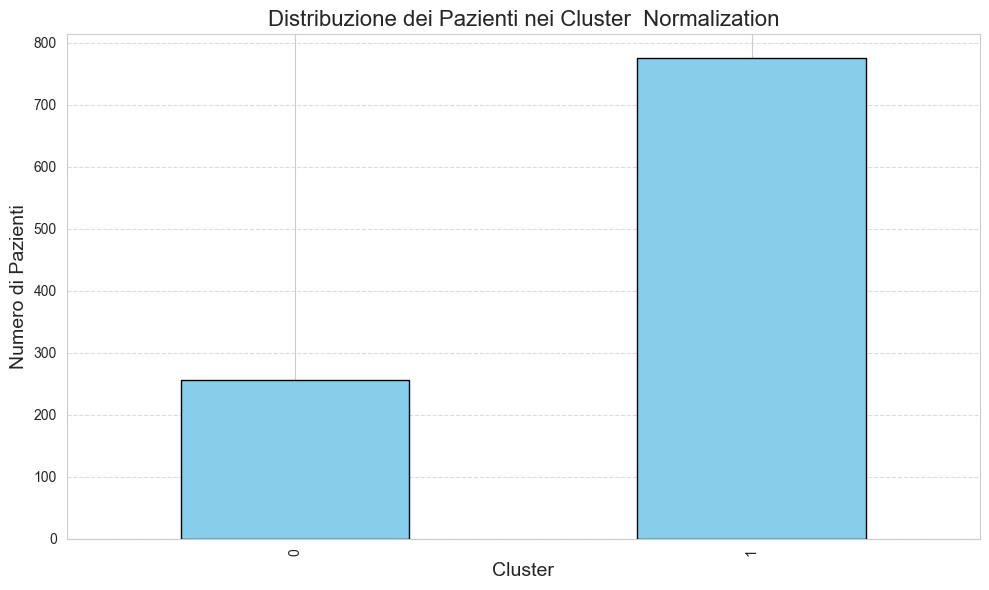

In [55]:
from sklearn.decomposition import PCA

centroids = pd.DataFrame(scaler_minmax.inverse_transform(kmeans.cluster_centers_), columns=features)
print(f"Centroidi dei Cluster:")
print(centroids)

# Analisi della distribuzione nei cluster
print(f"\nDistribuzione nei Cluster:")
cluster_distribution = patients_df.groupby(f'cluster')[features].mean()
print(cluster_distribution)

# Visualizzazione dei cluster
plt.figure(figsize=(10, 6))
patients_df[f'cluster'].value_counts().sort_index().plot(kind='bar', color='skyblue', edgecolor='black')
plt.title(f'Distribuzione dei Pazienti nei Cluster  Normalization', fontsize=16)
plt.xlabel('Cluster', fontsize=14)
plt.ylabel('Numero di Pazienti', fontsize=14)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show() # {1: 777, 0: 310}

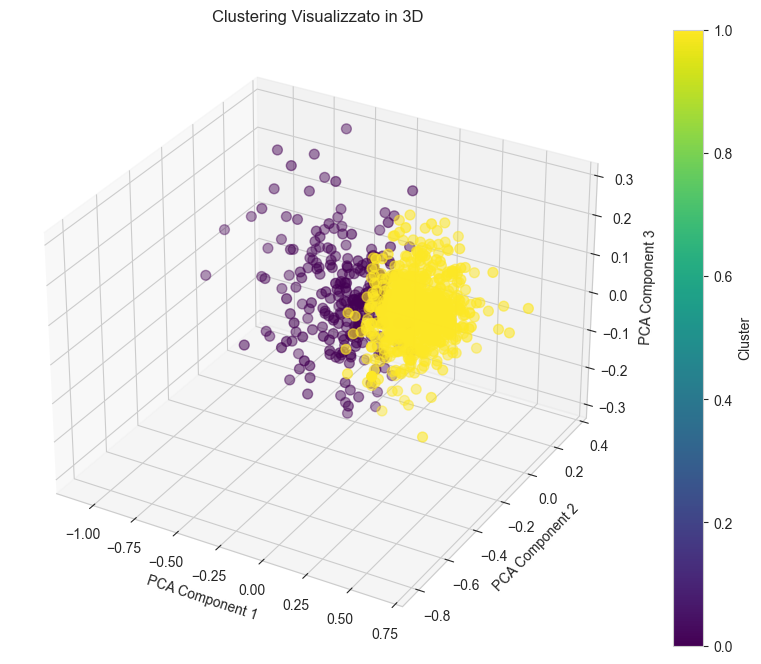

In [56]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

from mpl_toolkits.mplot3d import Axes3D

# Riduci i dati a 3 dimensioni con PCA
pca = PCA(n_components=3)
data_3d = pca.fit_transform(normalized_df)

# Aggiungi le componenti PCA al DataFrame
patients_df['PCA1'] = data_3d[:, 0]
patients_df['PCA2'] = data_3d[:, 1]
patients_df['PCA3'] = data_3d[:, 2]

# Crea un grafico 3D
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Visualizza i cluster
scatter = ax.scatter(patients_df['PCA1'], patients_df['PCA2'], patients_df['PCA3'],
                     c=patients_df['cluster'], cmap='viridis', s=50)

# Aggiungi etichette e legenda
ax.set_title('Clustering Visualizzato in 3D')
ax.set_xlabel('PCA Component 1')
ax.set_ylabel('PCA Component 2')
ax.set_zlabel('PCA Component 3')
plt.colorbar(scatter, label='Cluster')
plt.show()


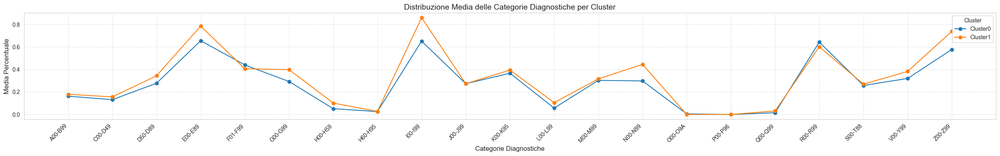

In [57]:
import matplotlib.pyplot as plt
import pandas as pd

# Assicurati che le categorie diagnostiche siano interpretate correttamente
patients_df['diagnosis_categories'] = patients_df['diagnosis_categories'].apply(
    lambda x: eval(x) if isinstance(x, str) else x)

# Lista delle categorie diagnostiche
cat = [
    'A00-B99', 'C00-D49', 'D50-D89', 'E00-E89', 'F01-F99', 'G00-G99', 'H00-H59', 'H60-H95',
    'I00-I99', 'J00-J99', 'K00-K95', 'L00-L99', 'M00-M99', 'N00-N99', 'O00-O9A', 'P00-P96',
    'Q00-Q99', 'R00-R99', 'S00-T88', 'V00-Y99', 'Z00-Z99'
]
# Calcola le medie per ogni categoria per cluster
centers = []
for cluster in patients_df['cluster'].unique():
    cluster_data = patients_df[patients_df['cluster'] == cluster]
    cluster_means = []
    for category in cat:
        # Calcola la percentuale di pazienti con quella categoria diagnostica
        cluster_means.append(
            cluster_data['diagnosis_categories'].apply(lambda x: category in x).mean()
        )
    centers.append(cluster_means)

# Genera il grafico
plt.figure(figsize=(25, 4))
for i in range(len(centers)):
    plt.plot(centers[i], marker='o', label=f'Cluster{i}')

# Configura gli assi
plt.xticks(range(len(cat)), cat, fontsize=10, rotation=45, ha='right')
plt.xlabel("Categorie Diagnostiche", fontsize=12)
plt.ylabel("Media Percentuale", fontsize=12)
plt.legend(fontsize=10, title="Cluster")
plt.grid(True, linestyle='--', alpha=0.6)

# Mostra il grafico
plt.title("Distribuzione Media delle Categorie Diagnostiche per Cluster", fontsize=14)
plt.tight_layout()
plt.show()


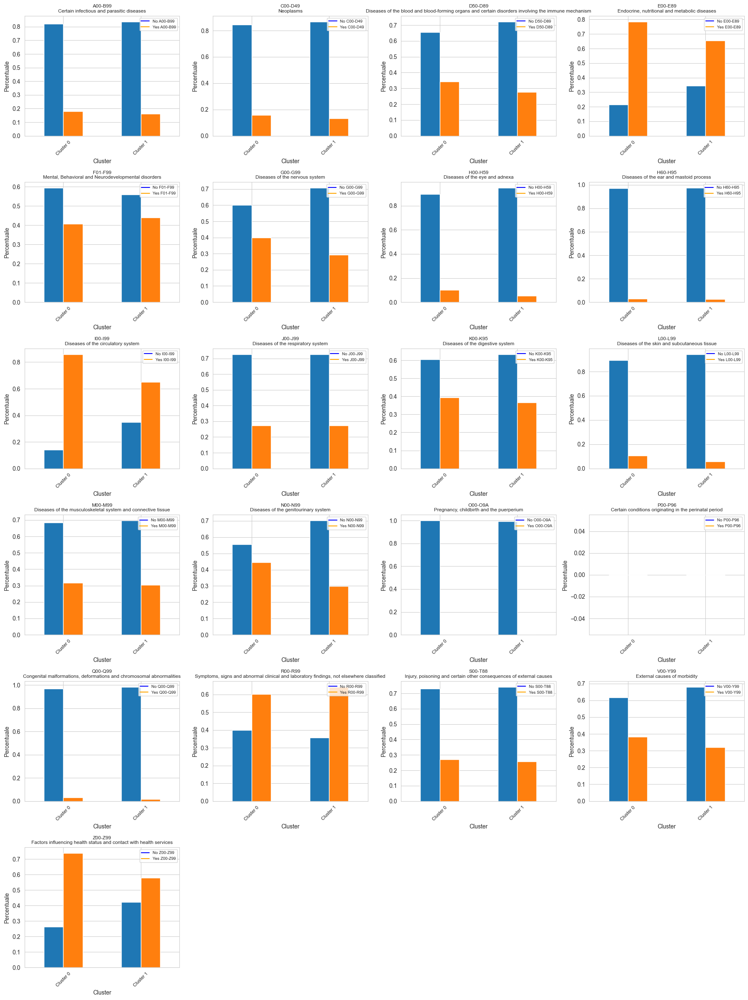

In [58]:
import matplotlib.pyplot as plt
import pandas as pd

icd10_category = pd.read_csv('../datasets/icd10_category.csv')
# Converti le categorie diagnostiche se necessario
patients_df['diagnosis_categories'] = patients_df['diagnosis_categories'].apply(
    lambda x: eval(x) if isinstance(x, str) else x)


def verify_diagnosis_category(category, ax):
    # Aggiungi colonna per indicare la presenza della categoria
    patients_df[f'has_{category}'] = patients_df['diagnosis_categories'].apply(lambda x: category in x)

    # Crea tabella di contingenza normalizzata
    diagnosis_categories_xt_pct = pd.crosstab(
        kmeans.labels_,  # Cluster
        patients_df[f'has_{category}'],  # Presenza della categoria
        normalize='index'  # Calcola le percentuali per ogni cluster
    )

    # Assicurati che ci siano sempre colonne per 'No' e 'Yes'
    expected_columns = [f'No {category}', f'Yes {category}']
    diagnosis_categories_xt_pct = diagnosis_categories_xt_pct.reindex(columns=[0, 1], fill_value=0)
    diagnosis_categories_xt_pct.columns = expected_columns

    # Plot del grafico
    diagnosis_categories_xt_pct.plot(kind='bar', stacked=False, ax=ax, legend=False)
    ax.set_title(f'{category}\n{icd10_category[icd10_category["Code_range"] == category]["Description"].iloc[0]}',
                 fontsize=8.5)
    ax.set_xlabel('Cluster')
    ax.set_ylabel('Percentuale')
    ax.set_xticks(range(len(diagnosis_categories_xt_pct)))
    ax.set_xticklabels([f'Cluster {i}' for i in diagnosis_categories_xt_pct.index], rotation=45, fontsize=8)

    # Aggiungi legenda manuale
    handles = [plt.Line2D([0], [0], color='blue', label=f'No {category}'),
               plt.Line2D([0], [0], color='orange', label=f'Yes {category}')]
    ax.legend(handles=handles, fontsize=7, loc='upper right')


# Lista delle categorie diagnostiche
cat = [
    'A00-B99', 'C00-D49', 'D50-D89', 'E00-E89', 'F01-F99', 'G00-G99', 'H00-H59', 'H60-H95',
    'I00-I99', 'J00-J99', 'K00-K95', 'L00-L99', 'M00-M99', 'N00-N99', 'O00-O9A', 'P00-P96',
    'Q00-Q99', 'R00-R99', 'S00-T88', 'V00-Y99', 'Z00-Z99'
]

# Configura il layout del grafico
n_cols = 4
n_rows = -(-len(cat) // n_cols)  # Calcola il numero di righe necessarie
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))

# Genera i grafici
for idx, category in enumerate(cat):
    row, col = divmod(idx, n_cols)
    ax = axes[row, col] if n_rows > 1 else axes[col]
    verify_diagnosis_category(category, ax)

# Rimuovi assi vuoti
for idx in range(len(cat), n_rows * n_cols):
    row, col = divmod(idx, n_cols)
    fig.delaxes(axes[row, col])

# Mostra il layout ottimizzato
plt.tight_layout()
plt.show()


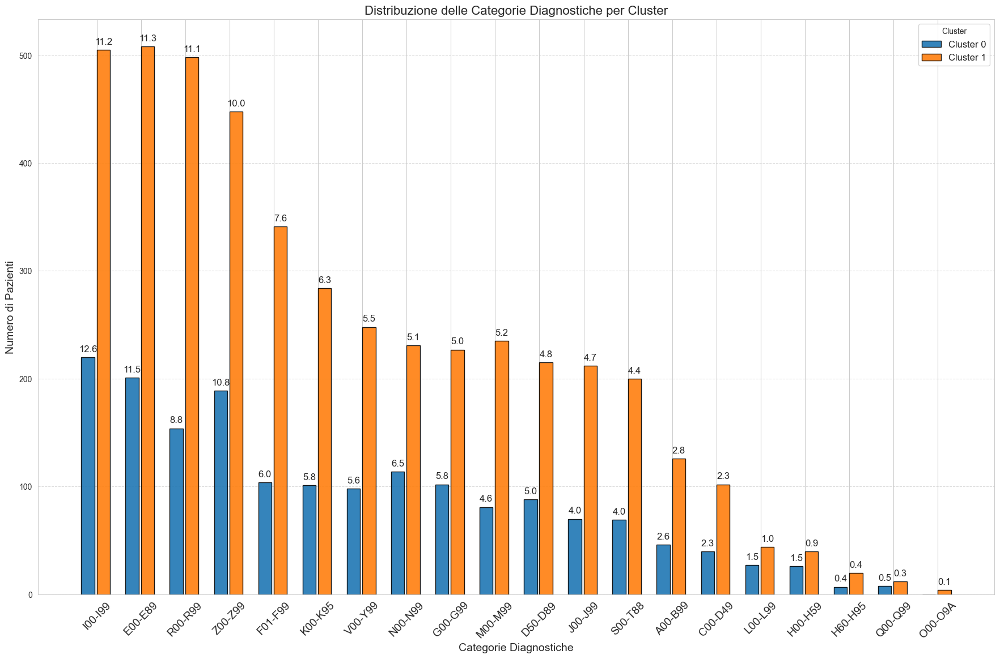

In [59]:
patients_df['diagnosis_categories'] = patients_df['diagnosis_categories'].apply(
    lambda x: eval(x) if isinstance(x, str) else x)

patients_expanded = patients_df.explode('diagnosis_categories')
cluster_groups = patients_expanded.groupby(['cluster', 'diagnosis_categories']).size().unstack(fill_value=0)
category_totals = cluster_groups.sum(axis=0).sort_values(ascending=False)
cluster_groups = cluster_groups[category_totals.index]
cluster_totals = cluster_groups.sum(axis=1)

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

plt.figure(figsize=(18, 12))

x = np.arange(len(cluster_groups.columns))
bar_width = 0.3
for i, cluster in enumerate(cluster_groups.index):
    values = cluster_groups.loc[cluster]
    percentages = (values / cluster_totals[cluster]) * 100
    positions = x + i * (bar_width + 0.05)
    plt.bar(positions, values, width=bar_width, label=f'Cluster {cluster}', color=colors[i % len(colors)],
            edgecolor='black', alpha=0.9)
    for pos, val, pct in zip(positions, values, percentages):
        if val > 0:
            plt.text(pos, val + 5, f'{pct:.1f}', ha='center', fontsize=12)

plt.xticks(x + ((bar_width + 0.1) * (len(cluster_groups.index) - 1)) / 2, cluster_groups.columns, rotation=45,
           fontsize=14)
plt.xlabel("Categorie Diagnostiche", fontsize=14)
plt.ylabel("Numero di Pazienti", fontsize=14)
plt.title("Distribuzione delle Categorie Diagnostiche per Cluster", fontsize=16)
plt.legend(fontsize=12, title="Cluster")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout(pad=2)
plt.show()


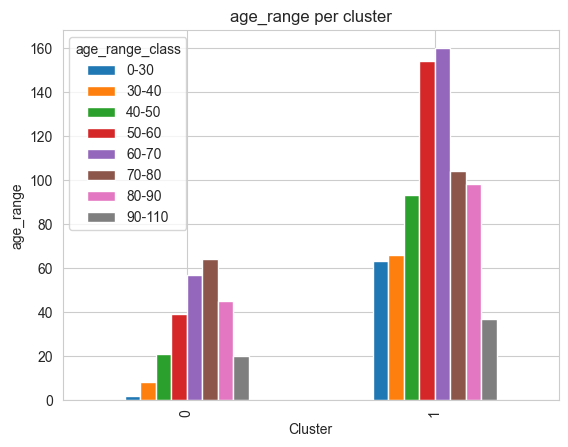

In [60]:
age_range_xt_pct = pd.crosstab(kmeans.labels_, patients_df['age_range_class'])
age_range_xt_pct
age_range_xt_pct.plot(kind='bar', stacked=False,
                      title='age_range per cluster')
plt.xlabel('Cluster')
plt.ylabel('age_range')
plt.show()

In [67]:
# Calcolo del numero di pazienti nel range di età 0-30 anni nei due cluster
# Filtra il dataset per considerare solo i pazienti nel range di età 0-30
patients_df_filtered = patients_df[(patients_df['age'] >= 0) & (patients_df['age'] <= 30)]

# Conta i pazienti in ciascun cluster
count_by_cluster = patients_df_filtered['cluster'].value_counts()

# Restituisce il conteggio per ogni cluster
count_by_cluster


cluster
1    63
0     2
Name: count, dtype: Int64

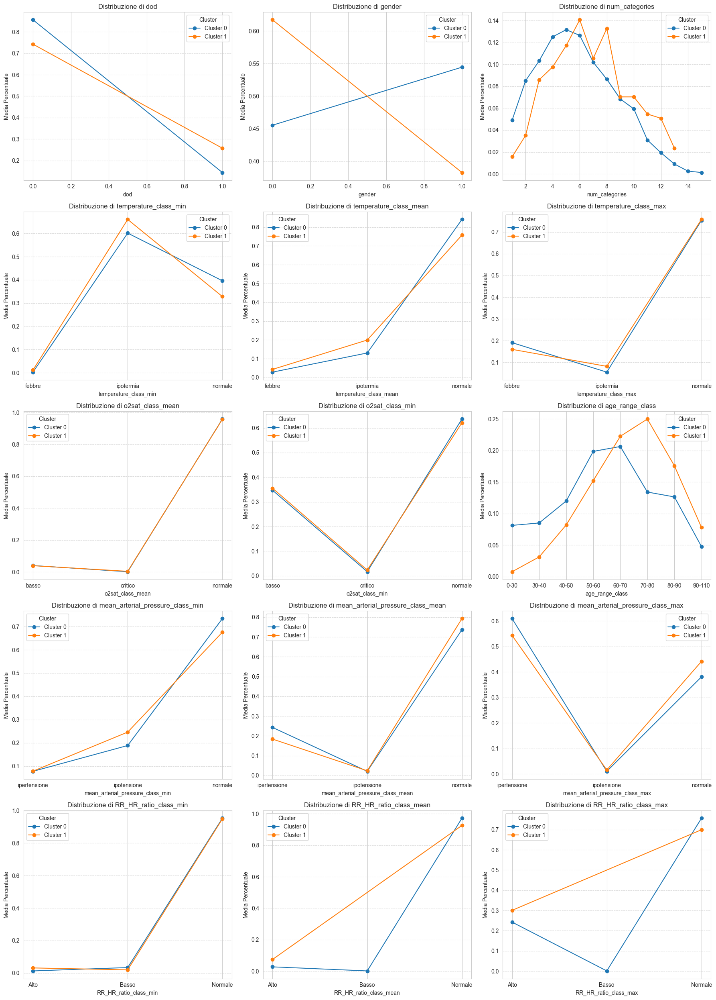

In [61]:
import matplotlib.pyplot as plt
import pandas as pd


# Funzione per generare i grafici a linee per la distribuzione media

def line_plot_view_clusters(cluster_attr, patients_df):
    # Attributi da analizzare
    attributes = ['dod', 'gender', 'num_categories',
                  'temperature_class_min', 'temperature_class_mean', 'temperature_class_max',
                  'o2sat_class_mean', 'o2sat_class_min',
                  'age_range_class', 'mean_arterial_pressure_class_min',
                  'mean_arterial_pressure_class_mean', 'mean_arterial_pressure_class_max',
                  'RR_HR_ratio_class_min', 'RR_HR_ratio_class_mean', 'RR_HR_ratio_class_max'
                  ]
    clusters = patients_df[cluster_attr].unique()
    n_cols = 3
    n_rows = -(-len(attributes) // n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))

    for idx, attr in enumerate(attributes):
        row = idx // n_cols
        col = idx % n_cols
        ax = axes[row, col]

        # Calcola le medie per ogni cluster
        centers = []
        for cluster in clusters:
            cluster_data = patients_df[patients_df[cluster_attr] == cluster]
            cluster_means = cluster_data.groupby(attr).size() / len(cluster_data)
            centers.append(cluster_means)

        # Genera il grafico per ogni cluster
        for i, cluster_means in enumerate(centers):
            ax.plot(cluster_means.index, cluster_means.values, marker='o', label=f'Cluster {i}')

        ax.set_title(f'Distribuzione di {attr}', fontsize=12)
        ax.set_xlabel(attr, fontsize=10)
        ax.set_ylabel('Media Percentuale', fontsize=10)
        ax.grid(axis='y', linestyle='--', alpha=0.7)
        ax.legend(title='Cluster')

    for i in range(len(attributes), n_rows * n_cols):
        fig.delaxes(axes.flat[i])

    plt.tight_layout()
    plt.show()


# Esegui la funzione
line_plot_view_clusters('cluster', patients_df)


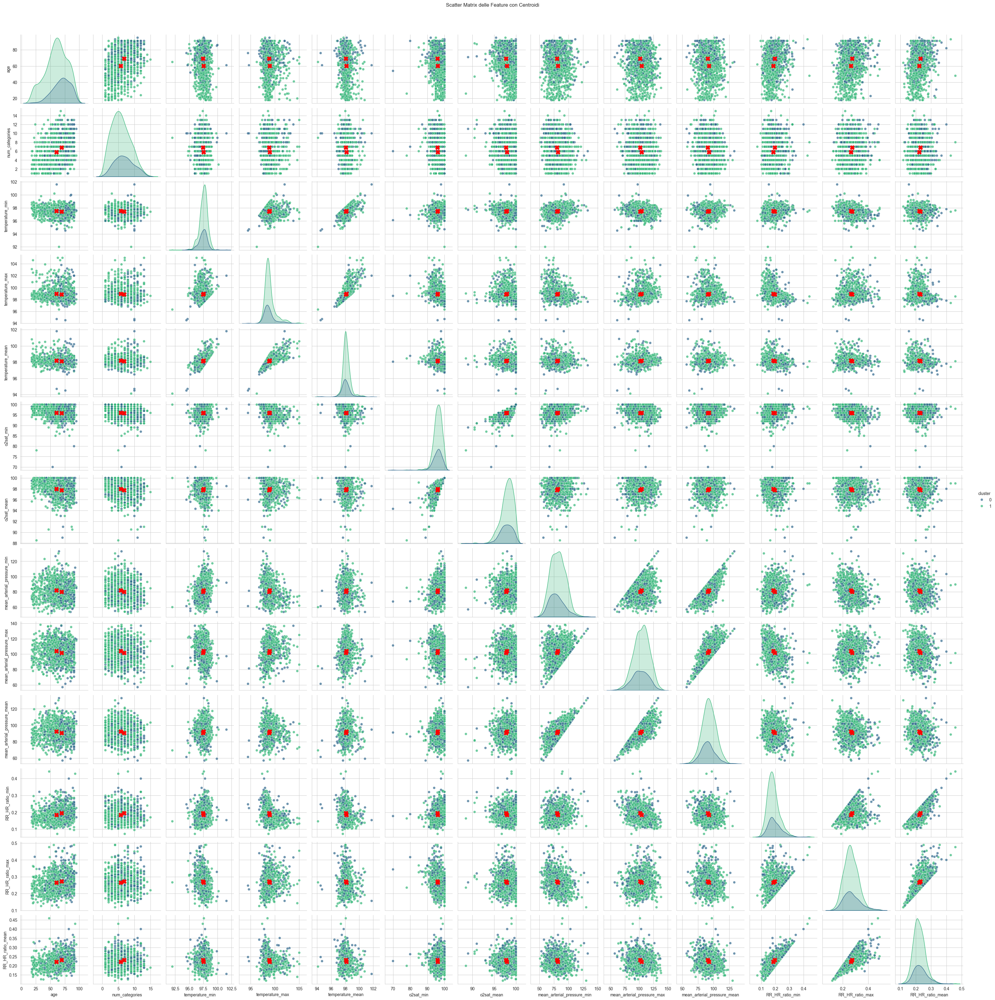

In [62]:
import seaborn as sns
f = ['age', 'num_categories',
     'temperature_min', 'temperature_max', 'temperature_mean', 'o2sat_min',
     'o2sat_mean', 'mean_arterial_pressure_min',
     'mean_arterial_pressure_max', 'mean_arterial_pressure_mean',
     'RR_HR_ratio_min', 'RR_HR_ratio_max', 'RR_HR_ratio_mean']
# Verifica e converte array/liste in valori scalari
for col in f + ['cluster']:
    if patients_df[col].apply(lambda x: isinstance(x, (list, np.ndarray))).any():
        patients_df[col] = patients_df[col].apply(lambda x: x[0] if isinstance(x, (list, np.ndarray)) else x)

# Converte le colonne in tipo numerico
for col in f:
    patients_df[col] = pd.to_numeric(patients_df[col], errors='coerce')

patients_df['cluster'] = pd.to_numeric(patients_df['cluster'], errors='coerce').astype('Int64')
subset = f + ['cluster']

# Rimuovi righe con NaN
features_df = patients_df.dropna(subset=subset)

# Calcola i centroidi per ogni cluster
centroids = features_df.groupby('cluster')[f].mean()

# Crea la scatter matrix
pairplot = sns.pairplot(features_df[subset], hue='cluster', palette='viridis', diag_kind='kde', plot_kws={'alpha': 0.7})


# Aggiungi i centroidi ai grafici
def add_centroids(ax, x_feature, y_feature):
    for cluster, centroid in centroids.iterrows():
        ax.scatter(
            centroid[x_feature], centroid[y_feature],
            color='red', marker='X', s=100, label=f'Centroid Cluster {cluster}' if cluster == 0 else ""
        )


# Itera su tutti i grafici e aggiungi i centroidi
for ax in pairplot.axes.flatten():
    if ax is not None:  # Assicurati che l'asse esista
        x_label = ax.get_xlabel()
        y_label = ax.get_ylabel()
        if x_label in f and y_label in f:
            add_centroids(ax, x_label, y_label)

# Mostra il grafico
plt.suptitle("Scatter Matrix delle Feature con Centroidi", y=1.02)
plt.show()


---
## **DBSCAN** 
### Studio dei parametri di clustering per DBSCAN
- eps: La distanza massima tra due punti affinché possano essere considerati parte dello stesso cluster.
- min_samples: Il numero minimo di punti richiesti per formare un cluster.

In [32]:
import pandas as pd
from sklearn.preprocessing import StandardScaler, MinMaxScaler

patients_df = pd.read_csv("merged_patients_shannon.csv")
features = ['II', 'III', 'aVR', 'aVF', 'V5']
# Normalizzazione Min-Max
scaler_minmax = MinMaxScaler()
normalized_df = scaler_minmax.fit_transform(patients_df[features])
normalized_df

array([[0.48918276, 0.58458736, 0.43791409, 0.60381778, 0.54606738],
       [0.5562084 , 0.63853401, 0.51823424, 0.66951248, 0.56021067],
       [0.40075743, 0.55864519, 0.35956802, 0.50420313, 0.42886607],
       ...,
       [0.36313395, 0.59894878, 0.4875602 , 0.55529673, 0.5352354 ],
       [0.50749249, 0.92291686, 0.45859498, 0.72561417, 0.46876726],
       [0.24404541, 0.4303874 , 0.11040892, 0.44218311, 0.22080354]])

In [40]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.spatial.distance import pdist, squareform
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Gamma di valori per eps, min_samples
eps_values = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1, 0.15, 0.2, 0.25, 0.35, 0.60, 0.80, 1, 1.3, 1.6, 2]  # Aggiunti nuovi valori
min_samples_values = [3, 5, 7, 10, 15, 20]

# Risultati finali
results = []

# Normalizza i dati
X = normalized_df

# Itera su eps e min_samples
for eps in eps_values:
    for min_samples in min_samples_values:
        # Esegui DBSCAN
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        labels = dbscan.fit_predict(X)

        # Calcola il numero di cluster (escludendo il rumore)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_points = list(labels).count(-1)

        # Calcola la distribuzione dei punti nei cluster
        cluster_distribution = {}
        if n_clusters > 0:
            unique_labels, counts = np.unique(labels[labels != -1], return_counts=True)
            cluster_distribution = dict(zip(unique_labels, counts))

        # Calcola le metriche solo se ci sono almeno due cluster
        if n_clusters > 1:
            silhouette = silhouette_score(X, labels)
            davies_bouldin = davies_bouldin_score(X, labels)
            results.append({
                "eps": eps,
                "min_samples": min_samples,
                "clusters": n_clusters,
                "noise_points": noise_points,
                "silhouette": silhouette,
                "davies_bouldin": davies_bouldin,
                "cluster_distribution": cluster_distribution
            })
        else:
            silhouette = -1  # Valore predefinito se non ci sono cluster validi
            davies_bouldin = np.inf

        # Salva i risultati
        
        # print(f"kth_distances_eps_{eps}_min_samples_{min_samples}")

# Crea un DataFrame per analizzare i risultati
param_dbscan_df = pd.DataFrame(results)


In [41]:
param_dbscan_df

,eps,min_samples,clusters,noise_points,silhouette,davies_bouldin,cluster_distribution
0,0.02,3,5,1005,-0.431833,2.672563,"{0: 3, 1: 8, 2: 3, 3: 3, 4: 9}"
1,0.03,3,21,862,-0.498361,3.065394,"{0: 12, 1: 75, 2: 8, 3: 4, 4: 3, 5: 3, 6: 4, 7: 8, 8: 14, 9: 3, 10: 3, 11: 3, 12: 3, 13: 3, 14: 3, 15: 5, 16: 3, 17: 3, 18: 3, 19: 3, 20: 3}"
2,0.03,5,6,933,-0.454562,4.081319,"{0: 7, 1: 55, 2: 7, 3: 7, 4: 10, 5: 12}"
3,0.03,7,4,987,-0.411293,2.972392,"{0: 17, 1: 15, 2: 5, 3: 7}"
4,0.03,10,2,1011,-0.362571,2.113670,"{0: 10, 1: 10}"
5,0.04,3,30,664,-0.470642,2.016416,"{0: 258, 1: 7, 2: 4, 3: 3, 4: 5, 5: 3, 6: 4, 7: 4, 8: 3, 9: 3, 10: 4, 11: 3, 12: 5, 13: 6, 14: 3, 15: 3, 16: 5, 17: 3, 18: 4, 19: 3, 20: 3, 21: 3, 22: 3, 23: 3, 24: 5, 25: 4, 26: 4, 27: 3, 28: 3, 29: 3}"
6,0.04,5,2,809,-0.249591,2.859624,"{0: 217, 1: 5}"
7,0.04,7,2,842,-0.277262,11.723464,"{0: 27, 1: 162}"
8,0.04,10,6,876,-0.365902,4.438094,"{0: 22, 1: 64, 2: 22, 3: 25, 4: 11, 5: 11}"
9,0.05,3,21,483,-0.415787,1.884934,"{0: 452, 1: 5, 2: 3, 3: 3, 4: 3, 5: 4, 6: 6, 7: 8, 8: 14, 9: 4, 10: 5, 11: 3, 12: 6, 13: 3, 14: 4, 15: 5, 16: 6, 17: 4, 18: 4, 19: 3, 20: 3}"


DBSCAN non e' un buon metodo per modelizzare i cluster di questo dataset. Visto che non vi e' un eps combinato con min_sample che dia una buona distribuzione di dati nei lcuster per poter fare un analisi.

---
## **Hierarchical**

In [51]:
import pandas as pd
from sklearn.preprocessing import StandardScaler, MinMaxScaler

patients_df = pd.read_csv("merged_patients_shannon.csv")
features = ['II', 'III', 'aVR', 'aVF', 'V6']
# Normalizzazione Min-Max
scaler_minmax = MinMaxScaler()
normalized_df = scaler_minmax.fit_transform(patients_df[features])
normalized_df

array([[0.48918276, 0.58458736, 0.43791409, 0.60381778, 0.48296313],
       [0.5562084 , 0.63853401, 0.51823424, 0.66951248, 0.54243212],
       [0.40075743, 0.55864519, 0.35956802, 0.50420313, 0.41278544],
       ...,
       [0.36313395, 0.59894878, 0.4875602 , 0.55529673, 0.56412567],
       [0.50749249, 0.92291686, 0.45859498, 0.72561417, 0.46888999],
       [0.24404541, 0.4303874 , 0.11040892, 0.44218311, 0.29817564]])

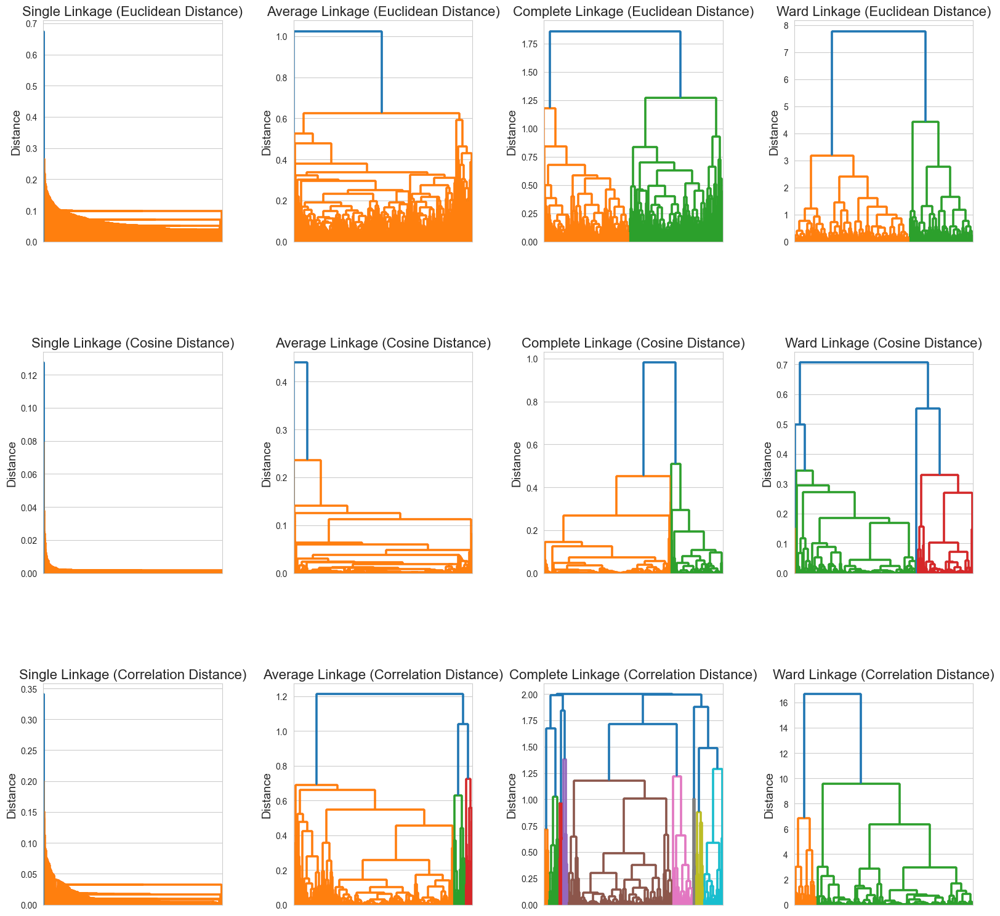

In [52]:
import os
import pandas as pd
import numpy as np
import scipy.cluster.hierarchy as sch
from scipy.spatial.distance import pdist
from matplotlib import pyplot as plt
import math

data = patients_df

# Ensure that the selected features are numeric
for col in features:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# Drop rows with missing values for the selected features
data = data.dropna(subset=features)

# Extract feature values for clustering
feature_values = normalized_df

# Distance Metrics and Linkage Methods
distance_metrics = ['euclidean', 'cosine', 'correlation']
linkage_methods = ['single', 'average', 'complete', 'ward']

# Threshold for cutting the dendrogram (adjust as needed)
threshold = [0.05, 0.06, 0.07, 0.08, 0.09, 0.1, 0.25, 0.5, 0.6, 0.7, 0.8, 0.9, 1, 1.1, 1, 2, 1.5, 1.7, 1.8, 2, 3, 3.5,
             4, 4.5, 5, 6, 7, 10, 15, 20, 25, 30]  # Heights for cutting the dendrogram

# Generate Dendrograms and calculate cluster distributions
results = []  # To store cluster distributions

fig, axes = plt.subplots(len(distance_metrics), len(linkage_methods), figsize=(16, len(distance_metrics) * 5))
axes = axes.flatten()

for tresh in threshold:
    for plot_idx, (metric, method) in enumerate([(m, l) for m in distance_metrics for l in linkage_methods]):
        # Compute the distance matrix
        distance_matrix = pdist(feature_values, metric=metric)

        # Perform hierarchical clustering
        linkage_matrix = sch.linkage(distance_matrix, method=method)

        # Assign clusters using fcluster
        clusters = sch.fcluster(linkage_matrix, t=tresh, criterion='distance')

        # Calculate the distribution of points in clusters
        cluster_counts = pd.Series(clusters).value_counts().to_dict()
        total_clusters = len(cluster_counts)  # Total number of clusters
        results.append({
            "Metric": metric,
            "Linkage": method,
            "Total_Clusters": total_clusters,
            "Threshold": tresh,
            "Cluster_Distribution": cluster_counts

        })

        # Plot dendrogram
        ax = axes[plot_idx]
        sch.dendrogram(
            linkage_matrix,
            no_labels=True,
            ax=ax
        )
        ax.set_title(f"{method.capitalize()} Linkage ({metric.capitalize()} Distance)", fontsize=16)
        ax.set_xlabel("")
        ax.set_ylabel("Distance", fontsize=14)

# Adjust layout
plt.tight_layout()
plt.subplots_adjust(hspace=0.5, wspace=0.4)
plt.show()

# Create a DataFrame with cluster distributions
cluster_results_df = pd.DataFrame(results)


Hierarchical predilige cluster di 2 e quello piu chiaro e' col metodo ward

Qui verranno solo considerati i seguenti per il calcolo del treshold e di conseguenza poi della silouhette e davies:
- Euclidean -> complete, ward
- Cosine -> complete
- Correlation -> average, ward

Calcolando la matrice delle distanze DTW...


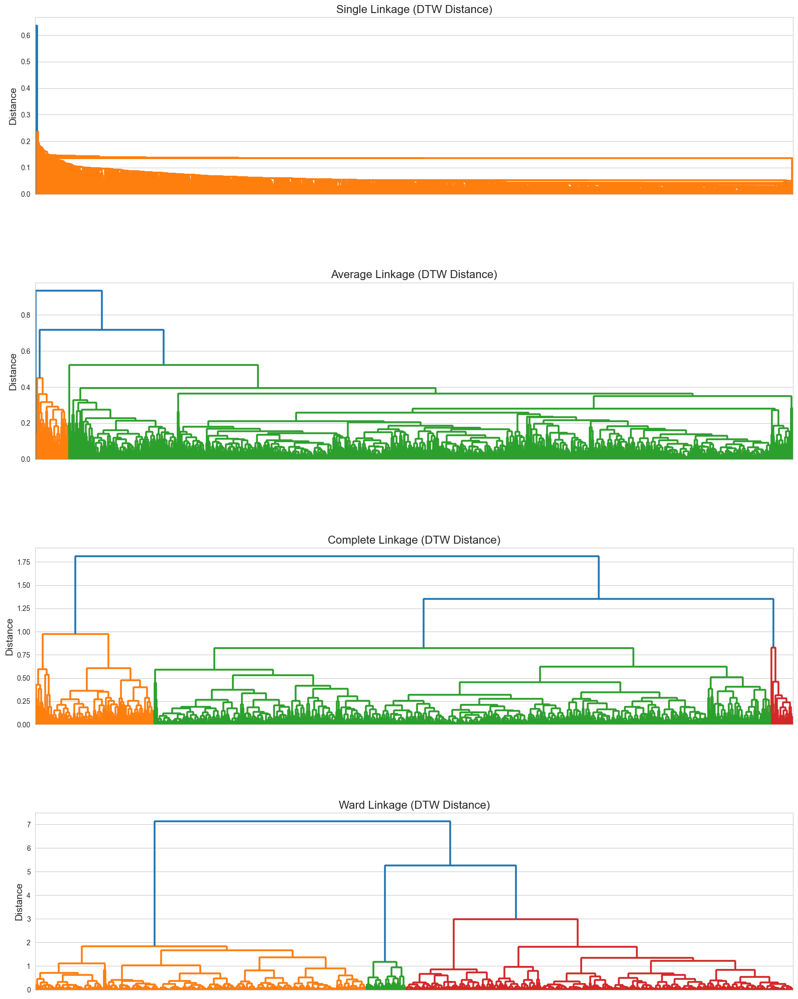

In [303]:
import os
import pandas as pd
import numpy as np
import scipy.cluster.hierarchy as sch
from dtaidistance.dtw import distance_matrix as dtw_distance_matrix
from scipy.spatial.distance import squareform
from matplotlib import pyplot as plt
import math

data = patients_df
features = ['II', 'III', 'aVR', 'aVF', 'V6']
# Ensure that the selected features are numeric
for col in features:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# Drop rows with missing values for the selected features
data = data.dropna(subset=features)

# Extract feature values for clustering
feature_values = normalized_df

# Distance Metrics and Linkage Methods
linkage_methods = ['single', 'average', 'complete', 'ward']

# Threshold for cutting the dendrogram (adjust as needed)
threshold = [0.05, 0.06, 0.07, 0.08, 0.09, 0.1, 0.25, 0.5, 0.6, 0.7, 0.8, 0.9, 1, 1.1, 1, 2, 1.5, 1.7, 1.8, 2, 3, 3.5,
             4, 4.5, 5, 6, 7, 10, 15, 20, 25,
             30]  # Heights for cutting the dendrogram

# Generate Dendrograms and calculate cluster distributions
results = []  # To store cluster distributions

fig, axes = plt.subplots(len(linkage_methods), 1, figsize=(16, len(linkage_methods) * 5))
axes = axes.flatten()

# Calcolo della matrice delle distanze con DTW
print("Calcolando la matrice delle distanze DTW...")
distance_matrix = dtw_distance_matrix(feature_values)

# Converte la matrice in forma condensata
condensed_distance_matrix = squareform(distance_matrix)

for tresh in threshold:
    for plot_idx, method in enumerate(linkage_methods):
        # Perform hierarchical clustering
        linkage_matrix = sch.linkage(condensed_distance_matrix, method=method)

        # Assign clusters using fcluster
        clusters = sch.fcluster(linkage_matrix, t=tresh, criterion='distance')

        # Calculate the distribution of points in clusters
        cluster_counts = pd.Series(clusters).value_counts().to_dict()
        total_clusters = len(cluster_counts)  # Total number of clusters
        results.append({
            "Metric": "DTW",
            "Linkage": method,
            "Threshold": tresh,
            "Cluster_Distribution": cluster_counts,
            "Total_Clusters": total_clusters
        })

        # Plot dendrogram
        ax = axes[plot_idx]
        sch.dendrogram(
            linkage_matrix,
            no_labels=True,
            ax=ax
        )
        ax.set_title(f"{method.capitalize()} Linkage (DTW Distance)", fontsize=16)
        ax.set_xlabel("")
        ax.set_ylabel("Distance", fontsize=14)

# Adjust layout
plt.tight_layout()
plt.subplots_adjust(hspace=0.5, wspace=0.4)
plt.show()

# Create a DataFrame with cluster distributions
cluster_dtw_df = pd.DataFrame(results)

# Visualizza i risultati
# print(cluster_results_df[['Metric', 'Linkage', 'Threshold', 'Cluster_Distribution', 'Total_Clusters']])
# 
# # Salva in un file CSV (opzionale)
# cluster_results_df.to_csv("hierarchical_cluster_results_dtw.csv", index=False)


In [304]:
cluster_dtw_df

,Metric,Linkage,Threshold,Cluster_Distribution,Total_Clusters
0,DTW,single,0.05,"{189: 511, 162: 8, 198: 7, 118: 6, 183: 6, 179: 6, 169: 5, 146: 5, 138: 4, 182: 4, 171: 4, 187: 4, 133: 4, 175: 3, 160: 3, 176: 3, 185: 3, 164: 3, 148: 3, 178: 2, 30: 2, 68: 2, 99: 2, 98: 2, 82: 2, 186: 2, 166: 2, 115: 2, 112: 2, 144: 2, 167: 2, 87: 2, 199: 2, 170: 2, 153: 2, 114: 2, 177: 2, 103: 2, 110: 2, 73: 2, 188: 2, 161: 2, 137: 2, 111: 2, 174: 2, 147: 2, 77: 2, 139: 2, 28: 1, 283: 1, 18: 1, 370: 1, 125: 1, 25: 1, 173: 1, 53: 1, 196: 1, 347: 1, 235: 1, 257: 1, 376: 1, 378: 1, 293: 1, 74: 1, 253: 1, 320: 1, 122: 1, 222: 1, 377: 1, 149: 1, 157: 1, 348: 1, 246: 1, 96: 1, 66: 1, 10: 1, 120: 1, 406: 1, 353: 1, 415: 1, 21: 1, 31: 1, 85: 1, 180: 1, 417: 1, 145: 1, 396: 1, 268: 1, 67: 1, 414: 1, 92: 1, 404: 1, 208: 1, 217: 1, 231: 1, 403: 1, 260: 1, 38: 1, 94: 1, 205: 1, ...}",429
1,DTW,average,0.05,"{589: 15, 254: 12, 256: 12, 260: 12, 579: 12, 560: 11, 578: 10, 557: 9, 302: 9, 382: 8, 570: 8, 381: 8, 558: 7, 590: 6, 252: 6, 387: 6, 468: 5, 369: 5, 101: 5, 288: 5, 258: 5, 575: 5, 344: 5, 214: 5, 255: 5, 253: 5, 79: 5, 554: 5, 581: 4, 301: 4, 482: 4, 559: 4, 366: 4, 217: 4, 300: 4, 222: 4, 249: 4, 516: 4, 394: 4, 592: 4, 388: 4, 308: 4, 380: 4, 189: 4, 375: 3, 418: 3, 251: 3, 348: 3, 324: 3, 580: 3, 209: 3, 571: 3, 183: 3, 215: 3, 582: 3, 250: 3, 462: 3, 376: 3, 473: 3, 262: 3, 497: 3, 365: 3, 534: 3, 261: 3, 586: 3, 211: 3, 546: 3, 114: 3, 553: 3, 574: 3, 286: 3, 370: 3, 384: 3, 299: 3, 223: 3, 562: 3, 102: 3, 291: 3, 304: 3, 109: 3, 228: 3, 466: 3, 233: 3, 247: 3, 99: 3, 587: 3, 355: 2, 494: 2, 335: 2, 169: 2, 115: 2, 467: 2, 444: 2, 103: 2, 452: 2, 569: 2, 368: 2, 498: 2, 194: 2, 532: 2, ...}",622
2,DTW,complete,0.05,"{146: 9, 339: 7, 370: 7, 372: 7, 378: 7, 143: 6, 376: 6, 498: 5, 380: 5, 371: 5, 365: 5, 187: 5, 167: 4, 403: 4, 336: 4, 373: 4, 145: 4, 377: 4, 430: 4, 411: 4, 214: 4, 534: 4, 283: 4, 412: 4, 141: 4, 535: 4, 368: 4, 561: 4, 215: 4, 486: 4, 485: 4, 564: 4, 381: 4, 483: 4, 489: 4, 319: 4, 148: 3, 164: 3, 585: 3, 151: 3, 281: 3, 410: 3, 154: 3, 402: 3, 567: 3, 149: 3, 622: 3, 296: 3, 405: 3, 350: 3, 478: 3, 172: 3, 56: 3, 613: 3, 379: 3, 482: 3, 144: 3, 501: 3, 533: 3, 156: 3, 477: 3, 415: 3, 468: 3, 147: 3, 300: 3, 142: 3, 188: 3, 41: 3, 398: 3, 408: 3, 341: 3, 53: 3, 611: 3, 358: 3, 160: 3, 507: 3, 558: 3, 338: 3, 404: 3, 299: 3, 218: 3, 153: 3, 347: 3, 39: 3, 310: 3, 364: 2, 304: 2, 54: 2, 462: 2, 253: 2, 479: 2, 210: 2, 413: 2, 68: 2, 234: 2, 420: 2, 434: 2, 209: 2, 189: 2, 444: 2, ...}",666
3,DTW,ward,0.05,"{488: 7, 112: 7, 44: 6, 239: 6, 114: 6, 129: 5, 48: 5, 533: 5, 492: 5, 473: 4, 671: 4, 668: 4, 204: 4, 135: 4, 666: 4, 588: 4, 181: 4, 675: 4, 529: 4, 139: 4, 672: 4, 117: 4, 325: 4, 89: 4, 554: 4, 584: 4, 119: 4, 489: 4, 660: 4, 237: 4, 209: 3, 131: 3, 547: 3, 484: 3, 642: 3, 667: 3, 421: 3, 39: 3, 440: 3, 479: 3, 591: 3, 592: 3, 363: 3, 59: 3, 33: 3, 76: 3, 232: 3, 41: 3, 189: 3, 586: 3, 532: 3, 491: 3, 231: 3, 35: 3, 474: 3, 527: 3, 184: 3, 551: 3, 161: 3, 548: 3, 210: 3, 118: 3, 115: 3, 485: 3, 480: 3, 557: 3, 581: 3, 438: 3, 238: 3, 121: 3, 49: 3, 327: 3, 650: 3, 105: 3, 179: 3, 127: 3, 111: 3, 653: 3, 229: 3, 37: 3, 478: 3, 662: 2, 200: 2, 208: 2, 180: 2, 568: 2, 251: 2, 362: 2, 107: 2, 654: 2, 357: 2, 335: 2, 186: 2, 74: 2, 78: 2, 144: 2, 648: 2, 194: 2, 228: 2, 32: 2, ...}",676
4,DTW,single,0.06,"{103: 700, 102: 10, 101: 4, 71: 4, 91: 4, 94: 3, 30: 3, 99: 3, 100: 2, 90: 2, 58: 2, 82: 2, 88: 2, 87: 2, 98: 2, 73: 2, 84: 2, 95: 2, 81: 2, 66: 2, 93: 2, 97: 2, 78: 2, 64: 1, 27: 1, 279: 1, 270: 1, 157: 1, 147: 1, 52: 1, 10: 1, 25: 1, 184: 1, 234: 1, 217: 1, 110: 1, 145: 1, 28: 1, 18: 1, 242: 1, 211: 1, 121: 1, 240: 1, 241: 1, 212: 1, 218: 1, 170: 1, 249: 1, 280: 1, 65: 1, 278: 1, 86: 1, 268: 1, 267: 1, 124: 1, 37: 1, 158: 1, 183: 1, 75: 1, 106: 1, 189: 1, 152: 1, 214: 1, 228: 1, 132: 1, 260: 1, 281: 1, 40: 1, 246: 1, 21: 1, 133: 1, 293: 1, 199: 1, 47: 1, 213: 1, 178: 1, 31: 1, 275: 1, 290: 1, 151: 1, 276: 1, 231: 1, 117: 1, 

In [278]:
# Filtra il DataFrame per distanza 'euclidean' e metodo di linkage 'complete'
euclidean_complete_df = cluster_results_df[
    (cluster_results_df['Metric'] == 'correlation') &
    (cluster_results_df['Linkage'] == 'ward')
    ]

# Visualizza il risultato
euclidean_complete_df

,Metric,Linkage,Total_Clusters,Threshold,Cluster_Distribution
11,correlation,ward,196,0.05,"{159: 43, 145: 36, 153: 30, 142: 28, 187: 27, 152: 26, 96: 25, 141: 24, 166: 21, 102: 19, 98: 17, 157: 15, 101: 14, 140: 14, 143: 13, 99: 13, 97: 13, 154: 12, 155: 12, 118: 12, 119: 11, 103: 11, 160: 11, 121: 11, 117: 10, 185: 10, 189: 9, 112: 8, 184: 8, 151: 8, 76: 8, 134: 8, 186: 8, 133: 8, 116: 8, 149: 8, 89: 8, 144: 8, 120: 8, 110: 7, 139: 7, 165: 7, 156: 7, 164: 7, 77: 7, 163: 7, 74: 7, 158: 6, 162: 6, 176: 6, 115: 6, 135: 6, 122: 6, 114: 6, 90: 6, 61: 6, 192: 5, 1: 5, 111: 5, 126: 5, 73: 5, 100: 5, 195: 5, 170: 5, 125: 5, 188: 5, 146: 5, 124: 5, 85: 5, 171: 5, 181: 4, 161: 4, 39: 4, 177: 4, 172: 4, 40: 4, 137: 4, 93: 4, 20: 4, 84: 4, 113: 4, 196: 4, 92: 4, 17: 4, 58: 4, 71: 3, 87: 3, 80: 3, 173: 3, 23: 3, 25: 3, 193: 3, 60: 3, 178: 3, 36: 3, 168: 3, 28: 3, 11: 3, 22: 3, 179: 3, ...}"
23,correlation,ward,175,0.06,"{131: 44, 143: 43, 137: 30, 129: 28, 168: 27, 136: 26, 85: 25, 128: 24, 150: 21, 91: 19, 87: 17, 141: 15, 90: 14, 169: 14, 127: 14, 130: 13, 86: 13, 88: 13, 139: 12, 107: 12, 138: 12, 110: 11, 135: 11, 108: 11, 144: 11, 92: 11, 154: 10, 106: 10, 166: 10, 78: 8, 134: 8, 158: 8, 105: 8, 101: 8, 109: 8, 165: 8, 120: 8, 121: 8, 167: 8, 67: 8, 68: 7, 99: 7, 140: 7, 126: 7, 65: 7, 64: 7, 147: 7, 149: 7, 112: 7, 148: 7, 53: 6, 69: 6, 104: 6, 122: 6, 111: 6, 103: 6, 146: 6, 173: 6, 79: 6, 142: 6, 89: 5, 1: 5, 172: 5, 51: 5, 46: 5, 100: 5, 114: 5, 75: 5, 174: 5, 132: 5, 113: 5, 4: 4, 13: 4, 81: 4, 77: 4, 155: 4, 34: 4, 35: 4, 74: 4, 15: 4, 175: 4, 159: 4, 163: 4, 102: 4, 145: 4, 124: 4, 82: 4, 29: 3, 8: 3, 161: 3, 73: 3, 23: 3, 7: 3, 14: 3, 156: 3, 31: 3, 164: 3, 70: 3, 52: 3, 133: 3, ...}"
35,correlation,ward,163,0.07,"{121: 44, 132: 43, 127: 30, 119: 28, 156: 27, 126: 26, 79: 25, 118: 24, 131: 21, 139: 21, 83: 19, 84: 19, 155: 18, 81: 17, 95: 14, 117: 14, 157: 14, 82: 13, 80: 13, 120: 13, 97: 12, 129: 12, 128: 12, 98: 11, 133: 11, 125: 11, 85: 11, 100: 11, 143: 10, 96: 10, 94: 10, 62: 8, 124: 8, 99: 8, 154: 8, 147: 8, 72: 8, 93: 8, 110: 8, 111: 8, 60: 7, 138: 7, 91: 7, 136: 7, 63: 7, 130: 7, 102: 7, 137: 7, 116: 7, 68: 7, 59: 7, 135: 6, 49: 6, 161: 6, 112: 6, 64: 6, 101: 6, 73: 6, 92: 5, 69: 5, 104: 5, 47: 5, 160: 5, 42: 5, 11: 5, 1: 5, 103: 5, 162: 5, 122: 5, 31: 4, 76: 4, 32: 4, 144: 4, 4: 4, 75: 4, 71: 4, 14: 4, 114: 4, 134: 4, 27: 4, 163: 4, 12: 4, 152: 4, 148: 4, 21: 3, 141: 3, 13: 3, 123: 3, 44: 3, 48: 3, 113: 3, 8: 3, 19: 3, 22: 3, 150: 3, 28: 3, 61: 3, 24: 3, 146: 3, 153: 3, ...}"
47,correlation,ward,148,0.08,"{111: 52, 113: 44, 123: 43, 119: 30, 76: 30, 141: 27, 118: 26, 74: 25, 120: 24, 110: 21, 128: 21, 122: 21, 77: 19, 78: 19, 140: 18, 126: 14, 89: 14, 142: 14, 75: 13, 130: 13, 112: 13, 91: 12, 124: 11, 79: 11, 92: 11, 117: 11, 94: 11, 125: 10, 88: 10, 90: 10, 93: 8, 139: 8, 134: 8, 57: 8, 105: 8, 116: 8, 104: 8, 87: 8, 136: 8, 67: 8, 54: 7, 121: 7, 96: 7, 55: 7, 58: 7, 85: 7, 127: 7, 63: 7, 59: 6, 106: 6, 45: 6, 68: 6, 146: 6, 95: 6, 43: 5, 147: 5, 98: 5, 38: 5, 1: 5, 145: 5, 97: 5, 129: 5, 86: 5, 114: 5, 10: 5, 64: 5, 108: 4, 13: 4, 131: 4, 3: 4, 29: 4, 66: 4, 30: 4, 11: 4, 148: 4, 70: 4, 71: 4, 135: 4, 25: 4, 137: 4, 56: 3, 15: 3, 16: 3, 53: 3, 44: 3, 115: 3, 7: 3, 60: 3, 26: 3, 6: 3, 21: 3, 138: 3, 132: 3, 23: 3, 40: 3, 20: 3, 18: 3, 133: 3, 107: 3, 12: 3, ...}"
59,correlation,ward,143,0.09,"{116: 56, 109: 52, 111: 44, 120: 43, 74: 30, 137: 27, 136: 26, 72: 25, 117: 24, 119: 21, 125: 21, 108: 21, 76: 19, 75: 19, 87: 14, 138: 14, 123: 14, 110: 13, 73: 13, 127: 13, 89: 12, 90: 11, 115: 11, 121: 11, 77: 11, 92: 11, 54: 10, 86: 10, 122: 10, 88: 10, 131: 8, 133: 8, 114: 8, 103: 8, 91: 8, 55: 8, 85: 8, 65: 8, 102: 8, 118: 7, 124: 7, 56: 7, 83: 7, 94: 7, 53: 7, 61: 7, 93: 6, 141: 6, 44: 6, 66: 6, 104: 6, 57: 6, 126: 5, 1: 5, 96: 5, 142: 5, 37: 5, 62: 5, 10: 5, 140: 5, 95: 5, 84: 5, 42: 5, 112: 5, 143: 4, 69: 4, 64: 4, 28: 4, 13: 4, 132: 4, 68: 4, 128: 4, 29: 4, 3: 4, 11: 4, 106: 4, 134: 4, 26: 4, 25: 4, 130: 3, 32: 3, 1

Verrranno estrapolati solo quelli col treshold giusto rispetto al dendogramma

In [280]:
# Lista di condizioni specifiche
conditions = [
    {"Metric": "euclidean", "Linkage": "complete", "Threshold": 1.5},
    {"Metric": "euclidean", "Linkage": "ward", "Threshold": 4.5},
    {"Metric": "cosine", "Linkage": "complete", "Threshold": 0.60},
    {"Metric": "correlation", "Linkage": "average", "Threshold": 0.80},
    {"Metric": "correlation", "Linkage": "ward", "Threshold": 10}
]

# Filtra il DataFrame in base alle condizioni
filtered_dfs = []
for condition in conditions:
    filtered_dfs.append(cluster_results_df[
                            (cluster_results_df['Metric'] == condition['Metric']) &
                            (cluster_results_df['Linkage'] == condition['Linkage']) &
                            (cluster_results_df['Threshold'] == condition['Threshold'])
                            ])

# Combina tutti i risultati filtrati in un unico DataFrame
final_filtered_df = pd.concat(filtered_dfs, ignore_index=True)

# Mostra i risultati
final_filtered_df

# (Facoltativo) Salva il risultato in un file CSV
# final_filtered_df.to_csv("filtered_cluster_results.csv", index=False)


,Metric,Linkage,Total_Clusters,Threshold,Cluster_Distribution
0,euclidean,complete,2,1.5,"{2: 535, 1: 496}"
1,euclidean,ward,2,4.5,"{1: 668, 2: 363}"
2,cosine,complete,2,0.6,"{1: 734, 2: 297}"
3,correlation,average,3,0.8,"{1: 924, 2: 67, 3: 40}"
4,correlation,ward,2,10.0,"{2: 899, 1: 132}"


---
## Silhouette e Davies

In [283]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.spatial.distance import pdist, squareform

# Inizializza una lista per i risultati
hierarchical_metrics = []

# Itera sul DataFrame filtrato
for index, row in final_filtered_df.iterrows():
    # Estrai i parametri dal DataFrame
    metric = row['Metric']
    linkage = row['Linkage']
    threshold = row['Threshold']
    n_clusters = row['Total_Clusters']
    # Filtra i dati delle features
    feature_values = normalized_df

    # Calcola la matrice delle distanze
    distance_matrix = pdist(feature_values, metric=metric)
    condensed_distance_matrix = squareform(distance_matrix)

    # Crea il linkage matrix per hierarchical clustering
    linkage_matrix = sch.linkage(distance_matrix, method=linkage)

    # Esegui il clustering con il threshold specificato
    clusters = sch.fcluster(linkage_matrix, t=threshold, criterion='distance')

    # Calcola le metriche se ci sono più di 1 cluster
    if len(set(clusters)) > 1:
        silhouette = silhouette_score(condensed_distance_matrix, clusters, metric='precomputed')
        davies_bouldin = davies_bouldin_score(feature_values, clusters)
    else:
        silhouette = -1  # Non applicabile
        davies_bouldin = float('inf')  # Non applicabile

    # Aggiungi i risultati
    hierarchical_metrics.append({
        "Metric": metric,
        "Linkage": linkage,
        "Threshold": threshold,
        "Total_Clusters": n_clusters,
        "Silhouette": silhouette,
        "Davies_Bouldin": davies_bouldin,
        "Cluster_Counts": dict(pd.Series(clusters).value_counts())
    })

# Crea un DataFrame con i risultati
hierarchical_metrics_df = pd.DataFrame(hierarchical_metrics)


In [284]:
hierarchical_metrics_df

,Metric,Linkage,Threshold,Total_Clusters,Silhouette,Davies_Bouldin,Cluster_Counts
0,euclidean,complete,1.5,2,0.273264,1.181220,"{2: 535, 1: 496}"
1,euclidean,ward,4.5,2,0.356013,1.093606,"{1: 668, 2: 363}"
2,cosine,complete,0.6,2,0.363110,2.422426,"{1: 734, 2: 297}"
3,correlation,average,0.8,3,0.567511,1.928841,"{1: 924, 2: 67, 3: 40}"
4,correlation,ward,10.0,2,0.671082,1.642660,"{2: 899, 1: 132}"


I migliori con un compromesso silouhette e davies piu equilibrato sono il ward di correlation e euclidean.
Pero' sara' fatta l'analisi considerando il miglior compromesso tra silouhette, davies e distribuzione dei dati nei cluster: **euclidean ward**

distribuzione kmeans : {1: 782, 0: 305}
distribuzione hierarchical: {1: 668, 2: 363}

---
### Analisi di clustering - HIERARCHICAL

In [1]:
import pandas as pd
from sklearn.preprocessing import StandardScaler, MinMaxScaler

patients_df = pd.read_csv("merged_patients_shannon.csv")
features = ['II', 'III', 'aVR', 'aVF', 'V6']
# Normalizzazione Min-Max
scaler_minmax = MinMaxScaler()
normalized_df = scaler_minmax.fit_transform(patients_df[features])
normalized_df

array([[0.48918276, 0.58458736, 0.43791409, 0.60381778, 0.48296313],
       [0.5562084 , 0.63853401, 0.51823424, 0.66951248, 0.54243212],
       [0.40075743, 0.55864519, 0.35956802, 0.50420313, 0.41278544],
       ...,
       [0.36313395, 0.59894878, 0.4875602 , 0.55529673, 0.56412567],
       [0.50749249, 0.92291686, 0.45859498, 0.72561417, 0.46888999],
       [0.24404541, 0.4303874 , 0.11040892, 0.44218311, 0.29817564]])

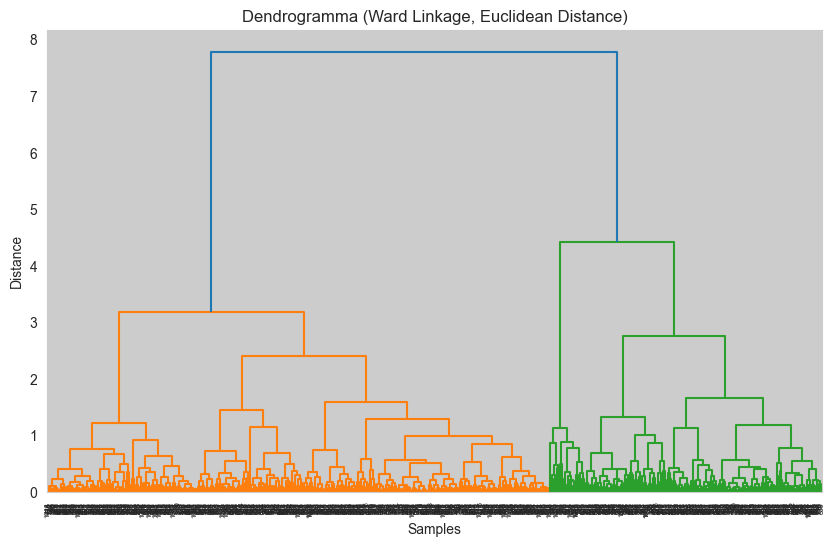

In [3]:
from scipy.spatial.distance import pdist
import scipy.cluster.hierarchy as sch
import matplotlib.pyplot as plt
# Calcola la matrice delle distanze
distance_matrix = pdist(normalized_df, metric='euclidean')
# Costruisci il linkage matrix
linkage_matrix = sch.linkage(distance_matrix, method='ward')
# Plot del dendrogramma
plt.figure(figsize=(10, 6))
sch.dendrogram(linkage_matrix)
plt.title("Dendrogramma (Ward Linkage, Euclidean Distance)")
plt.xlabel("Samples")
plt.ylabel("Distance")
plt.show()



In [4]:
from scipy.cluster.hierarchy import fcluster

# Taglia il dendrogramma per ottenere i cluster
threshold = 4.5  # Sostituisci con il valore identificato
clusters = fcluster(linkage_matrix, t=threshold, criterion='distance')

# Conta il numero di cluster
n_clusters = len(set(clusters))
print(f"Numero di cluster: {n_clusters}")

# Aggiungi i cluster ai dati originali
patients_df['cluster'] = clusters

# Analizza la distribuzione
cluster_distribution = patients_df['cluster'].value_counts()
print(cluster_distribution)


Numero di cluster: 2
cluster
1    668
2    363
Name: count, dtype: int64


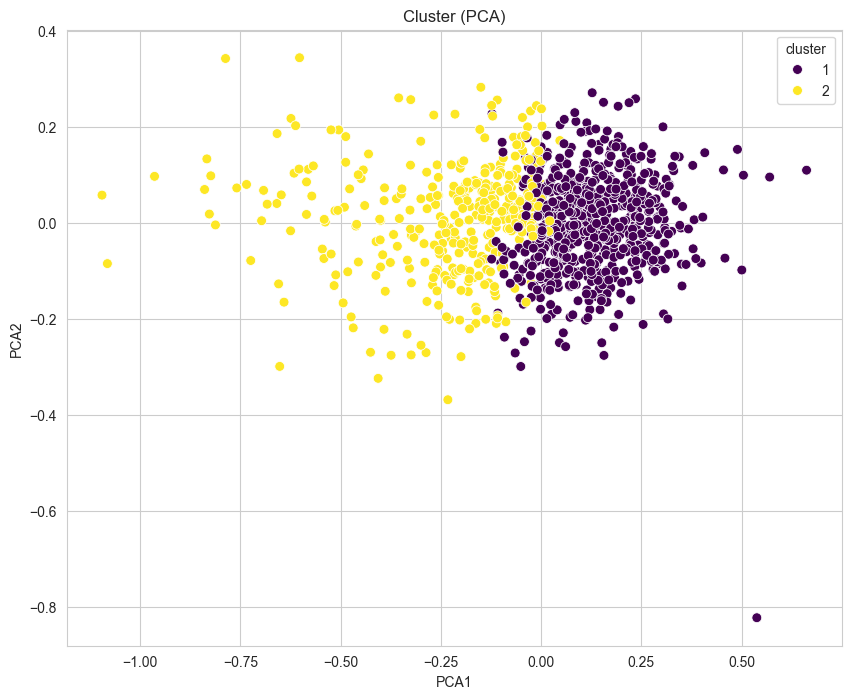

In [296]:
from sklearn.decomposition import PCA
import seaborn as sns

# Riduci i dati a 2 dimensioni
pca = PCA(n_components=2)
pca_result = pca.fit_transform(normalized_df)

# Crea un DataFrame con i risultati della PCA e i cluster
pca_df = pd.DataFrame(pca_result, columns=['PCA1', 'PCA2'])
pca_df['cluster'] = clusters

# Visualizza i cluster
plt.figure(figsize=(10, 8))
sns.scatterplot(data=pca_df, x='PCA1', y='PCA2', hue='cluster', palette='viridis', s=50)
plt.title("Cluster (PCA)")
plt.show()


[2 1]


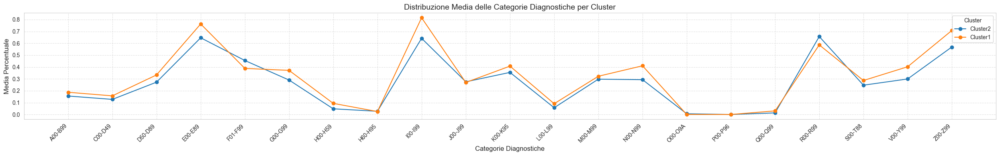

In [7]:
import matplotlib.pyplot as plt
import pandas as pd

# Assicurati che le categorie diagnostiche siano interpretate correttamente
patients_df['diagnosis_categories'] = patients_df['diagnosis_categories'].apply(
    lambda x: eval(x) if isinstance(x, str) else x)

# Lista delle categorie diagnostiche
cat = [
    'A00-B99', 'C00-D49', 'D50-D89', 'E00-E89', 'F01-F99', 'G00-G99', 'H00-H59', 'H60-H95',
    'I00-I99', 'J00-J99', 'K00-K95', 'L00-L99', 'M00-M99', 'N00-N99', 'O00-O9A', 'P00-P96',
    'Q00-Q99', 'R00-R99', 'S00-T88', 'V00-Y99', 'Z00-Z99'
]
# Calcola le medie per ogni categoria per cluster
centers = []
for cluster in patients_df['cluster'].unique():
    cluster_data = patients_df[patients_df['cluster'] == cluster]
    cluster_means = []
    for category in cat:
        # Calcola la percentuale di pazienti con quella categoria diagnostica
        cluster_means.append(
            cluster_data['diagnosis_categories'].apply(lambda x: category in x).mean()
        )
    centers.append(cluster_means)
print(patients_df['cluster'].unique())
# Genera il grafico
plt.figure(figsize=(25, 4))
for i in patients_df['cluster'].unique():
    plt.plot(centers[i-1], marker='o', label=f'Cluster{i}')

# Configura gli assi
plt.xticks(range(len(cat)), cat, fontsize=10, rotation=45, ha='right')
plt.xlabel("Categorie Diagnostiche", fontsize=12)
plt.ylabel("Media Percentuale", fontsize=12)
plt.legend(fontsize=10, title="Cluster")
plt.grid(True, linestyle='--', alpha=0.6)

# Mostra il grafico
plt.title("Distribuzione Media delle Categorie Diagnostiche per Cluster", fontsize=14)
plt.tight_layout()
plt.show()


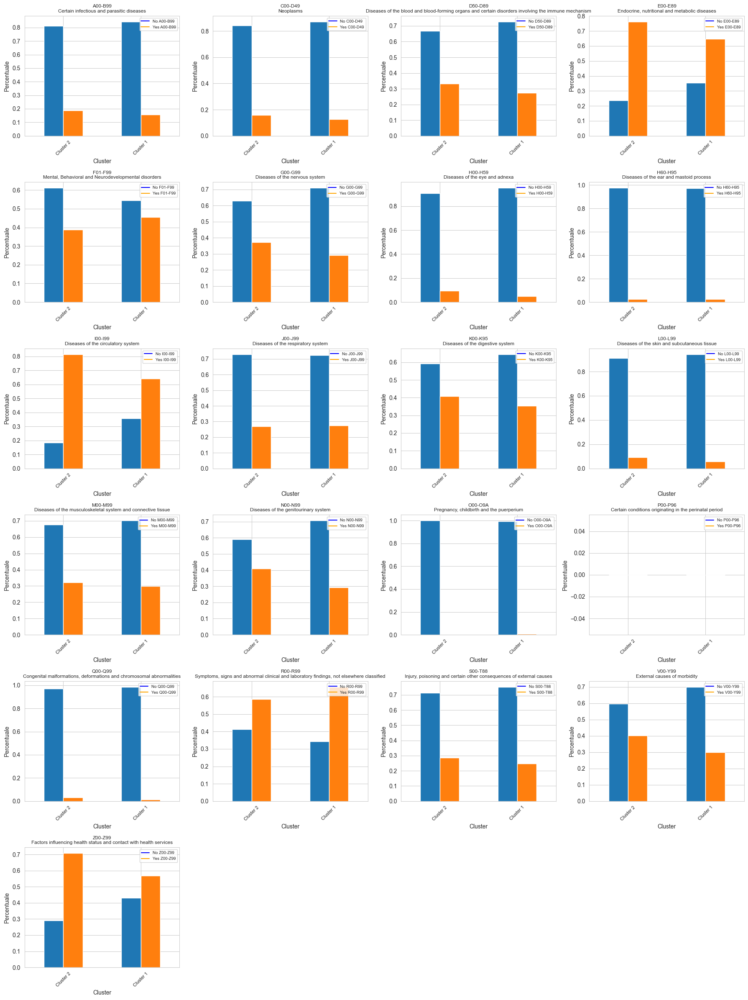

In [11]:
import matplotlib.pyplot as plt
import pandas as pd

icd10_category = pd.read_csv('../datasets/icd10_category.csv')
# Converti le categorie diagnostiche se necessario
patients_df['diagnosis_categories'] = patients_df['diagnosis_categories'].apply(
    lambda x: eval(x) if isinstance(x, str) else x)


def verify_diagnosis_category(category, ax):
    # Aggiungi colonna per indicare la presenza della categoria
    patients_df[f'has_{category}'] = patients_df['diagnosis_categories'].apply(lambda x: category in x)

    # Crea tabella di contingenza normalizzata
    diagnosis_categories_xt_pct = pd.crosstab(
        clusters,  # Cluster
        patients_df[f'has_{category}'],  # Presenza della categoria
        normalize='index'  # Calcola le percentuali per ogni cluster
    ).sort_index(ascending=False)  # Inverti l'ordine dei cluster


    # Assicurati che ci siano sempre colonne per 'No' e 'Yes'
    expected_columns = [f'No {category}', f'Yes {category}']
    diagnosis_categories_xt_pct = diagnosis_categories_xt_pct.reindex(columns=[0,1], fill_value=0)
    diagnosis_categories_xt_pct.columns = expected_columns

    # Plot del grafico
    diagnosis_categories_xt_pct.plot(kind='bar', stacked=False, ax=ax, legend=False)
    ax.set_title(f'{category}\n{icd10_category[icd10_category["Code_range"] == category]["Description"].iloc[0]}',
                 fontsize=8.5)
    ax.set_xlabel('Cluster')
    ax.set_ylabel('Percentuale')
    ax.set_xticks(range(len(diagnosis_categories_xt_pct)))
    ax.set_xticklabels([f'Cluster {i}' for i in diagnosis_categories_xt_pct.index], rotation=45, fontsize=8)

    # Aggiungi legenda manuale
    handles = [plt.Line2D([0], [0], color='blue', label=f'No {category}'),
               plt.Line2D([0], [0], color='orange', label=f'Yes {category}')]
    ax.legend(handles=handles, fontsize=7, loc='upper right')


# Lista delle categorie diagnostiche
cat = [
    'A00-B99', 'C00-D49', 'D50-D89', 'E00-E89', 'F01-F99', 'G00-G99', 'H00-H59', 'H60-H95',
    'I00-I99', 'J00-J99', 'K00-K95', 'L00-L99', 'M00-M99', 'N00-N99', 'O00-O9A', 'P00-P96',
    'Q00-Q99', 'R00-R99', 'S00-T88', 'V00-Y99', 'Z00-Z99'
]

# Configura il layout del grafico
n_cols = 4
n_rows = -(-len(cat) // n_cols)  # Calcola il numero di righe necessarie
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))

# Genera i grafici
for idx, category in enumerate(cat):
    row, col = divmod(idx, n_cols)
    ax = axes[row, col] if n_rows > 1 else axes[col]
    verify_diagnosis_category(category, ax)

# Rimuovi assi vuoti
for idx in range(len(cat), n_rows * n_cols):
    row, col = divmod(idx, n_cols)
    fig.delaxes(axes[row, col])

# Mostra il layout ottimizzato
plt.tight_layout()
plt.show()


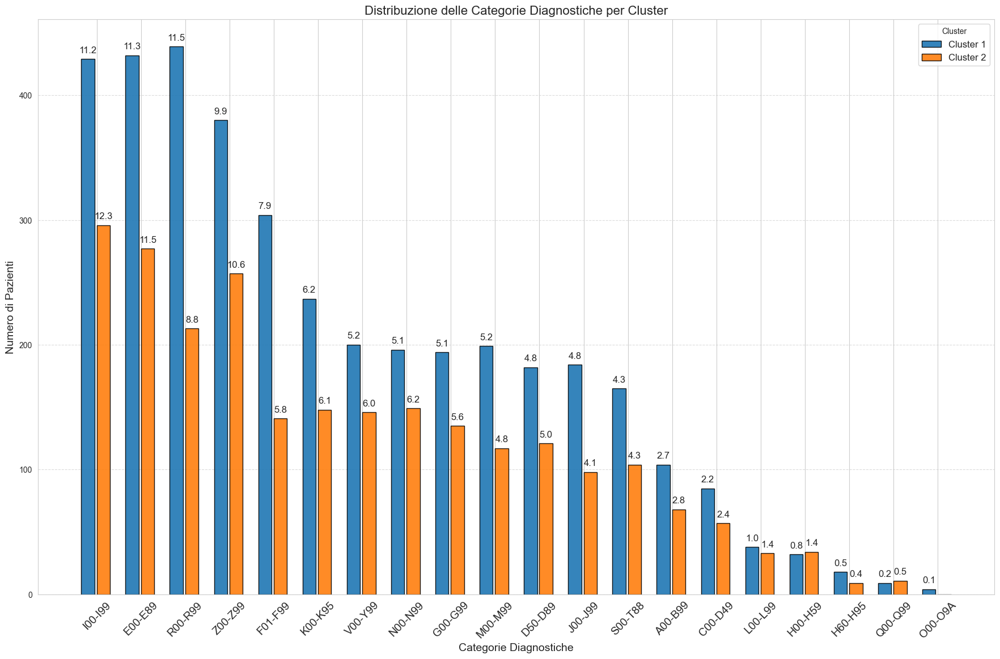

In [299]:
patients_df['diagnosis_categories'] = patients_df['diagnosis_categories'].apply(
    lambda x: eval(x) if isinstance(x, str) else x)

patients_expanded = patients_df.explode('diagnosis_categories')
cluster_groups = patients_expanded.groupby(['cluster', 'diagnosis_categories']).size().unstack(fill_value=0)
category_totals = cluster_groups.sum(axis=0).sort_values(ascending=False)
cluster_groups = cluster_groups[category_totals.index]
cluster_totals = cluster_groups.sum(axis=1)

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

plt.figure(figsize=(18, 12))

x = np.arange(len(cluster_groups.columns))
bar_width = 0.3
for i, cluster in enumerate(cluster_groups.index):
    values = cluster_groups.loc[cluster]
    percentages = (values / cluster_totals[cluster]) * 100
    positions = x + i * (bar_width + 0.05)
    plt.bar(positions, values, width=bar_width, label=f'Cluster {cluster}', color=colors[i % len(colors)],
            edgecolor='black', alpha=0.9)
    for pos, val, pct in zip(positions, values, percentages):
        if val > 0:
            plt.text(pos, val + 5, f'{pct:.1f}', ha='center', fontsize=12)

plt.xticks(x + ((bar_width + 0.1) * (len(cluster_groups.index) - 1)) / 2, cluster_groups.columns, rotation=45,
           fontsize=14)
plt.xlabel("Categorie Diagnostiche", fontsize=14)
plt.ylabel("Numero di Pazienti", fontsize=14)
plt.title("Distribuzione delle Categorie Diagnostiche per Cluster", fontsize=16)
plt.legend(fontsize=12, title="Cluster")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout(pad=2)
plt.show()


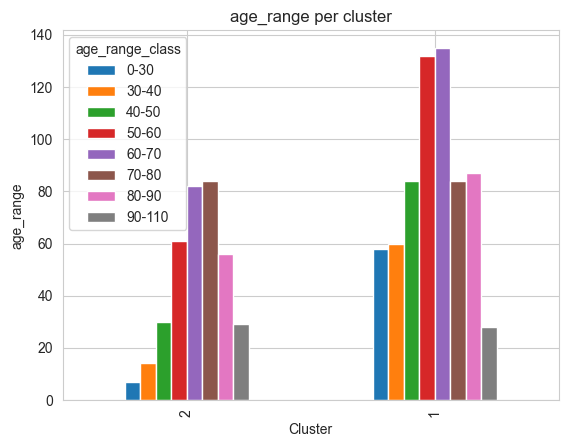

In [15]:
# Crea tabella di contingenza
age_range_xt_pct = pd.crosstab(clusters, patients_df['age_range_class'])

# Inverti l'ordine dei cluster
age_range_xt_pct = age_range_xt_pct.sort_index(ascending=False)

# Plot del grafico
age_range_xt_pct.plot(kind='bar', stacked=False, title='age_range per cluster')
plt.xlabel('Cluster')
plt.ylabel('age_range')
plt.show()


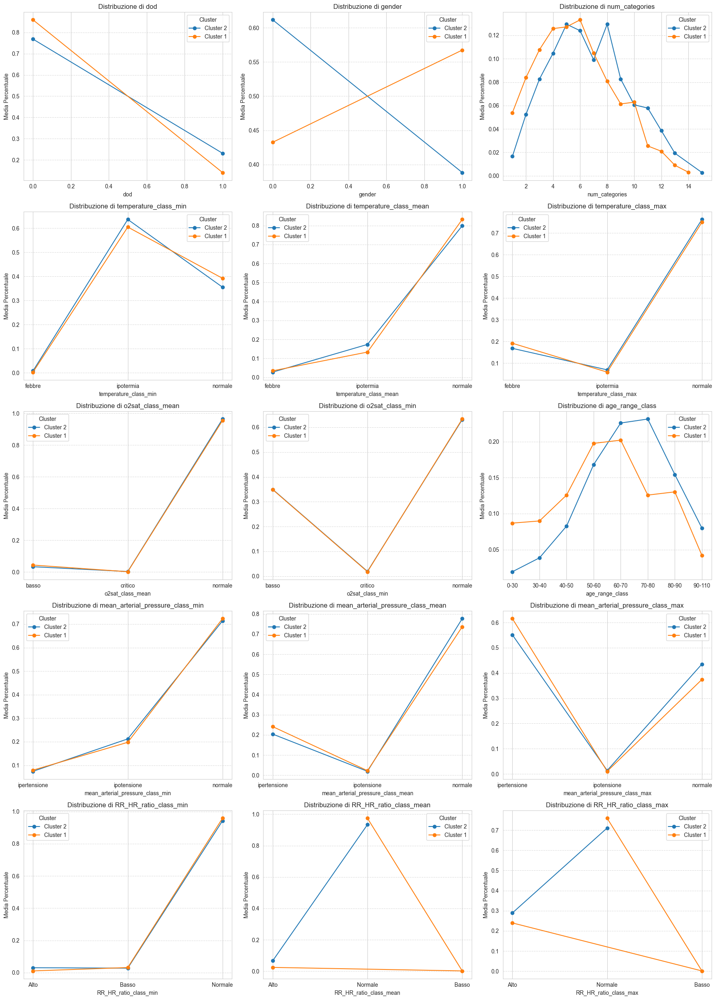

In [18]:
import matplotlib.pyplot as plt
import pandas as pd

# Funzione per generare i grafici a linee per la distribuzione media
def line_plot_view_clusters(cluster_attr, patients_df):
    # Attributi da analizzare
    attributes = ['dod', 'gender', 'num_categories',
                  'temperature_class_min', 'temperature_class_mean', 'temperature_class_max',
                  'o2sat_class_mean', 'o2sat_class_min',
                  'age_range_class', 'mean_arterial_pressure_class_min',
                  'mean_arterial_pressure_class_mean', 'mean_arterial_pressure_class_max',
                  'RR_HR_ratio_class_min', 'RR_HR_ratio_class_mean', 'RR_HR_ratio_class_max'
                  ]

    # Ordina i cluster in modo decrescente
    clusters = sorted(patients_df[cluster_attr].unique(), reverse=True)

    n_cols = 3
    n_rows = -(-len(attributes) // n_cols)  # Calcola il numero di righe necessario
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))

    for idx, attr in enumerate(attributes):
        row = idx // n_cols
        col = idx % n_cols
        ax = axes[row, col]

        # Calcola le medie per ogni cluster
        centers = []
        for cluster in clusters:
            cluster_data = patients_df[patients_df[cluster_attr] == cluster]
            cluster_means = cluster_data.groupby(attr).size() / len(cluster_data)
            centers.append(cluster_means)

        # Genera il grafico per ogni cluster
        for i, cluster_means in enumerate(centers):
            ax.plot(cluster_means.index, cluster_means.values, marker='o', label=f'Cluster {clusters[i]}')

        ax.set_title(f'Distribuzione di {attr}', fontsize=12)
        ax.set_xlabel(attr, fontsize=10)
        ax.set_ylabel('Media Percentuale', fontsize=10)
        ax.grid(axis='y', linestyle='--', alpha=0.7)
        ax.legend(title='Cluster')

    # Rimuovi gli assi vuoti
    for i in range(len(attributes), n_rows * n_cols):
        fig.delaxes(axes.flat[i])

    plt.tight_layout()
    plt.show()

# Esegui la funzione
line_plot_view_clusters('cluster', patients_df)


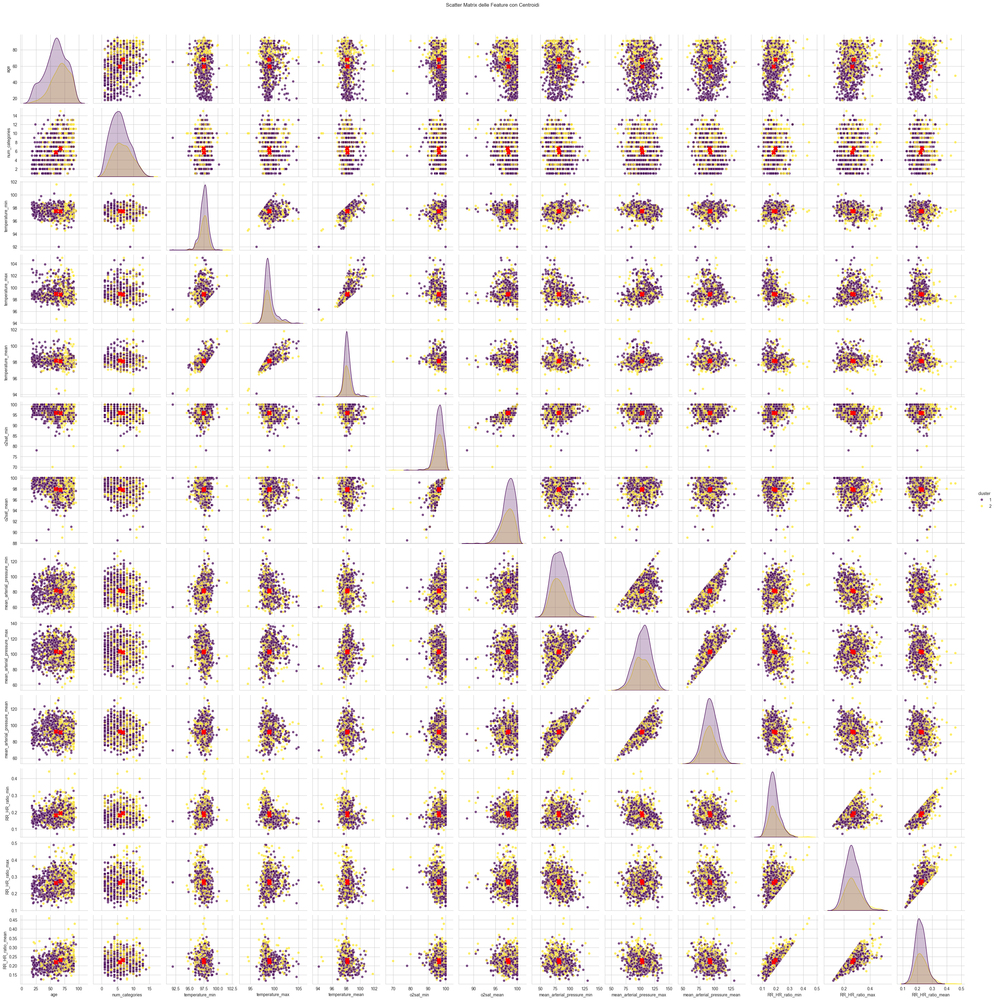

In [302]:
f = ['age', 'num_categories',
     'temperature_min', 'temperature_max', 'temperature_mean', 'o2sat_min',
     'o2sat_mean', 'mean_arterial_pressure_min',
     'mean_arterial_pressure_max', 'mean_arterial_pressure_mean',
     'RR_HR_ratio_min', 'RR_HR_ratio_max', 'RR_HR_ratio_mean']
# Verifica e converte array/liste in valori scalari
for col in f + ['cluster']:
    if patients_df[col].apply(lambda x: isinstance(x, (list, np.ndarray))).any():
        patients_df[col] = patients_df[col].apply(lambda x: x[0] if isinstance(x, (list, np.ndarray)) else x)

# Converte le colonne in tipo numerico
for col in f:
    patients_df[col] = pd.to_numeric(patients_df[col], errors='coerce')

patients_df['cluster'] = pd.to_numeric(patients_df['cluster'], errors='coerce').astype('Int64')
subset = f + ['cluster']

# Rimuovi righe con NaN
features_df = patients_df.dropna(subset=subset)

# Calcola i centroidi per ogni cluster
centroids = features_df.groupby('cluster')[f].mean()

# Crea la scatter matrix
pairplot = sns.pairplot(features_df[subset], hue='cluster', palette='viridis', diag_kind='kde', plot_kws={'alpha': 0.7})


# Aggiungi i centroidi ai grafici
def add_centroids(ax, x_feature, y_feature):
    for cluster, centroid in centroids.iterrows():
        ax.scatter(
            centroid[x_feature], centroid[y_feature],
            color='red', marker='X', s=100, label=f'Centroid Cluster {cluster}' if cluster == 0 else ""
        )


# Itera su tutti i grafici e aggiungi i centroidi
for ax in pairplot.axes.flatten():
    if ax is not None:  # Assicurati che l'asse esista
        x_label = ax.get_xlabel()
        y_label = ax.get_ylabel()
        if x_label in f and y_label in f:
            add_centroids(ax, x_label, y_label)

# Mostra il grafico
plt.suptitle("Scatter Matrix delle Feature con Centroidi", y=1.02)
plt.show()
